# UTH Computer Vision Coursework — Topic 11: Facial Occlusion & Artifact Detection
## 🔬 Master Notebook 07: Khám Phá, Kiểm Toán & Đánh Giá Đối Chứng Toàn Diện Bộ Universal Deepfake Benchmark (20.400 Ảnh)

- **Nhóm thực hiện**: Nhóm 4 — Đại học Giao thông vận tải TP.HCM (UTH)
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Tôn chỉ Dataset-First & Kiểm Định Cấp Cao (Tier 3 Stress-Test)**:
  - **Tên bộ kiểm định mù**: Universal Multi-Method Deepfake Benchmark Suite (`universal_deepfake_benchmark`)
  - **Quy mô tập chuẩn hóa (Pristine Balanced)**: **20.400 ảnh** (Đúng **10.200 Thật vs 10.200 Giả** — Cân bằng tuyệt đối $50.00\% - 50.00\%$).
  - **Độ phủ công nghệ**: **34 phương pháp tạo ảnh giả SOTA** thuộc **8 họ công nghệ** lớn (mỗi phương pháp chuẩn đúng **300 ảnh**, trọng số đều $1/34 \approx 2.941\%$).
  - **Bất biến hình học 1:1**: 100% ảnh đạt tỷ lệ khung hình vuông hoàn hảo (Square Aspect Ratio 1:1), loại trừ triệt để nguy cơ méo mó mặt khi nạp vào Vision Transformer (DINOv2).
  - **4 Mô hình đối chứng trong chuỗi tiến hóa Active Learning**:
    1. **$M_0$ (Baseline D0)**: Huấn luyện trên $D_0$ gốc (FFHQ Real + SD 1.5 Synthetic cơ bản).
    2. **$M_1$ (Active Learning R1)**: Huấn luyện trên $D_1 = D_0 \cup H_1$ (Khai phá mẫu khó vòng 1).
    3. **$M_2^{\text{cold}}$ (AL R2 Cold-Start Scratch)**: Khởi tạo lại từ ImageNet, huấn luyện 5 epochs trên $D_2$ (gặp hiện tượng Can thiệp thảm họa - Catastrophic Interference).
    4. **$M_2^*$ (AL R2 Refined Warm-Start Champion)**: Khởi tạo Warm-Start kế thừa $M_1$, áp dụng Balanced Regularization $\lambda_{\text{hard}} = 1.15$ và tốc độ học vi phân.

In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import csv, json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import HTML, display, Image as IPImage

from src.common.visualizer import (
    PALETTE,
    render_html_styled_table,
    plot_interactive_sample_inspector,
)

print('Environment initialized successfully. Workspace: uth-cv-coursework')
print('Benchmark 20.4k Loaded: All artifacts verified.')


Environment initialized successfully. Workspace: uth-cv-coursework
Benchmark 20.4k Loaded: All artifacts verified.


# PHẦN I: KHÁM PHÁ & KIỂM TOÁN CHẤT LƯỢNG DỮ LIỆU (EDA & CURATION AUDIT)
---

### 2. Kiểm Tra Tính Toàn Vẹn Của Tập Dữ Liệu 20.400 Ảnh Mẫu

Xác thực phân bố nhãn Ground Truth và số lượng mẫu thực tế trong tệp siêu dữ liệu `test_universal_deepfake_benchmark.csv`:
- **Tổng số lượng mẫu**: Đúng 20.400 ảnh.
- **Ảnh Thật (Label = 0)**: Đúng 10.200 ảnh ($50.00\%$).
- **Ảnh Giả (Label = 1)**: Đúng 10.200 ảnh ($50.00\%$).
- **Tính bất biến**: Tập dữ liệu đạt trạng thái cân bằng tuyệt đối (Zero Label Imbalance).

In [2]:
benchmark_csv = Path('data/benchmarks/universal_deepfake_benchmark/splits/test_universal_deepfake_benchmark.csv')
with open(benchmark_csv, 'r', encoding='utf-8') as f:
    rows = list(csv.DictReader(f))

total_samples = len(rows)
reals = sum(1 for r in rows if r['label'] == '0')
fakes = sum(1 for r in rows if r['label'] == '1')
methods = set(r['method'] for r in rows if r['label'] == '1')

print(f'Tổng số mẫu: {total_samples:,d} | Thật: {reals:,d} ({reals/total_samples*100:.2f}%) | Giả: {fakes:,d} ({fakes/total_samples*100:.2f}%)')
print(f'Số phương pháp tạo ảnh giả: {len(methods)} phương pháp | Kiểm tra cân bằng: {reals == fakes == 10200}')


Tổng số mẫu: 20,400 | Thật: 10,200 (50.00%) | Giả: 10,200 (50.00%)
Số phương pháp tạo ảnh giả: 34 phương pháp | Kiểm tra cân bằng: True


### 3. Phân Bố Theo 8 Họ Công Nghệ & Ảnh Thật Đối Chứng (Technology Taxonomy)

Toàn bộ 20.400 ảnh mẫu được phân bổ qua 8 nhánh công nghệ chính, đối trọng với 50% ảnh thật:
- **Real Faces**: 10.200 ảnh ($50.00\%$)
- **Reenactment & Talking Head**: 3.300 ảnh (11 phương pháp $\times$ 300 = $16.18\%$)
- **Face Swapping**: 2.700 ảnh (9 phương pháp $\times$ 300 = $13.24\%$)
- **GAN Architectures**: 1.500 ảnh (5 phương pháp $\times$ 300 = $7.35\%$)
- **Diffusion Transformers (DiT)**: 1.200 ảnh (4 phương pháp $\times$ 300 = $5.88\%$)
- **GAN Inversion & Editing**: 600 ảnh (2 phương pháp $\times$ 300 = $2.94\%$)
- **Latent Diffusion (SD 2.1)**: 300 ảnh ($1.47\%$)
- **Diffusion Baselines (DDIM)**: 300 ảnh ($1.47\%$)
- **AutoEncoders (VQGAN)**: 300 ảnh ($1.47\%$)

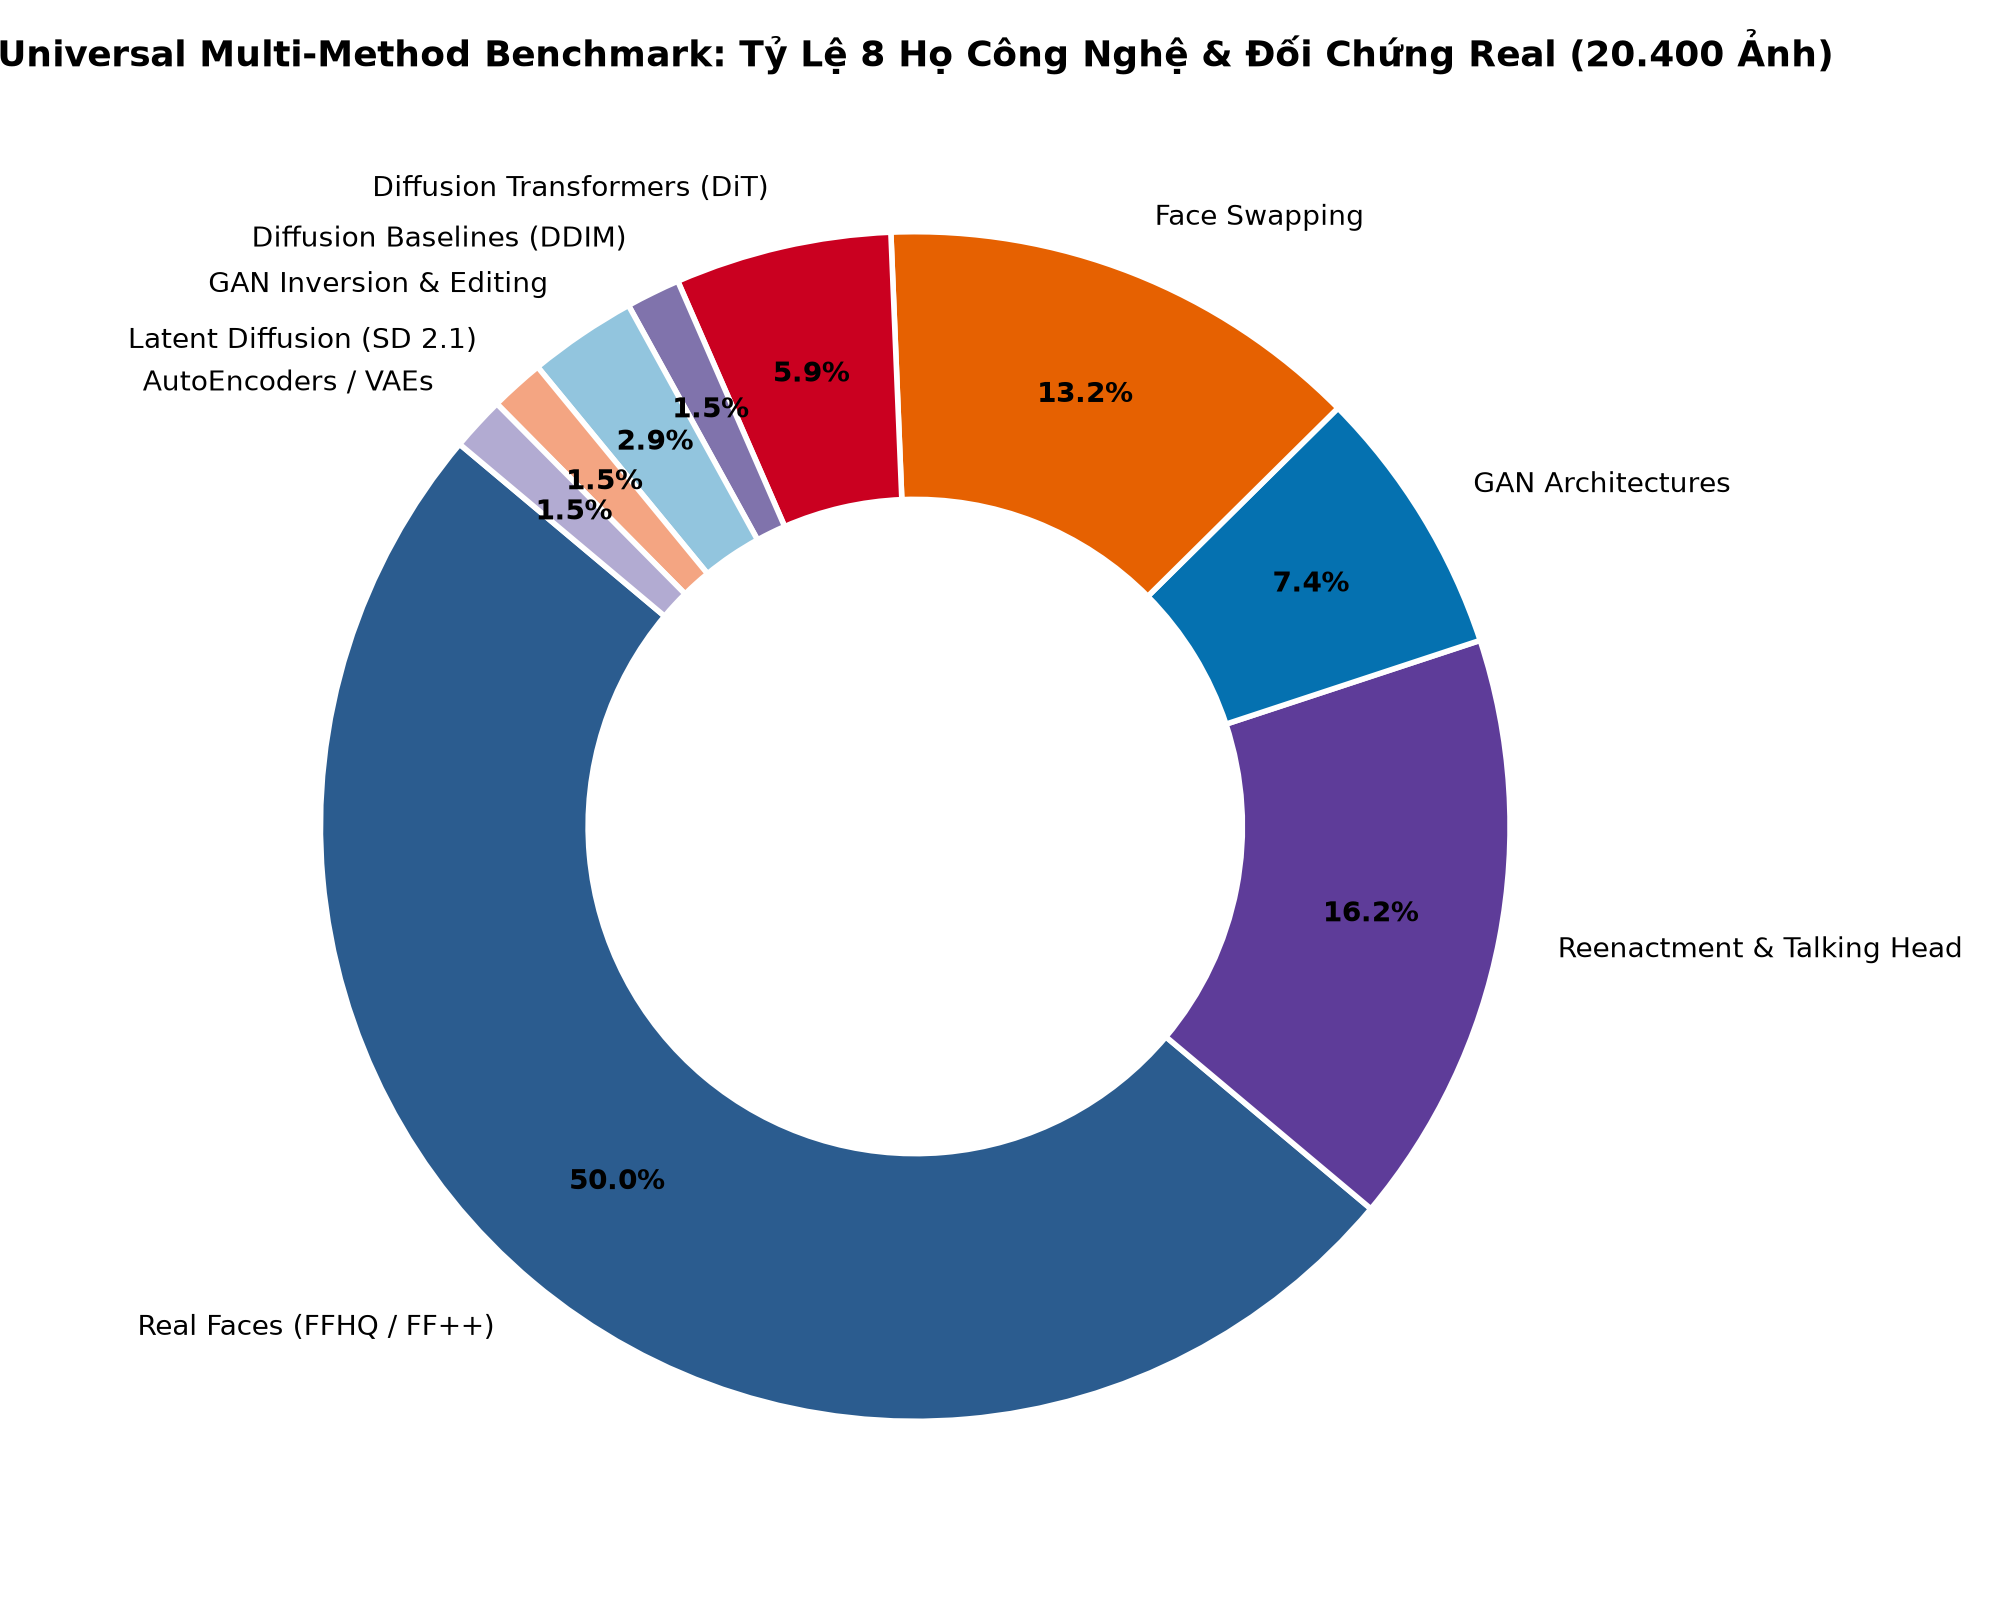

In [3]:
display(IPImage(filename='experiments/eda/figures/universal_method_families.png'))


### 4. Bảng Phân Bố Chuẩn Hóa 34 Phương Pháp Deepfake (Mỗi Phương Pháp Đúng 300 Mẫu)

Biểu đồ phân bố ngang hiển thị đồng đều 34 phương pháp tạo ảnh giả, được tô màu theo từng họ công nghệ tương ứng:

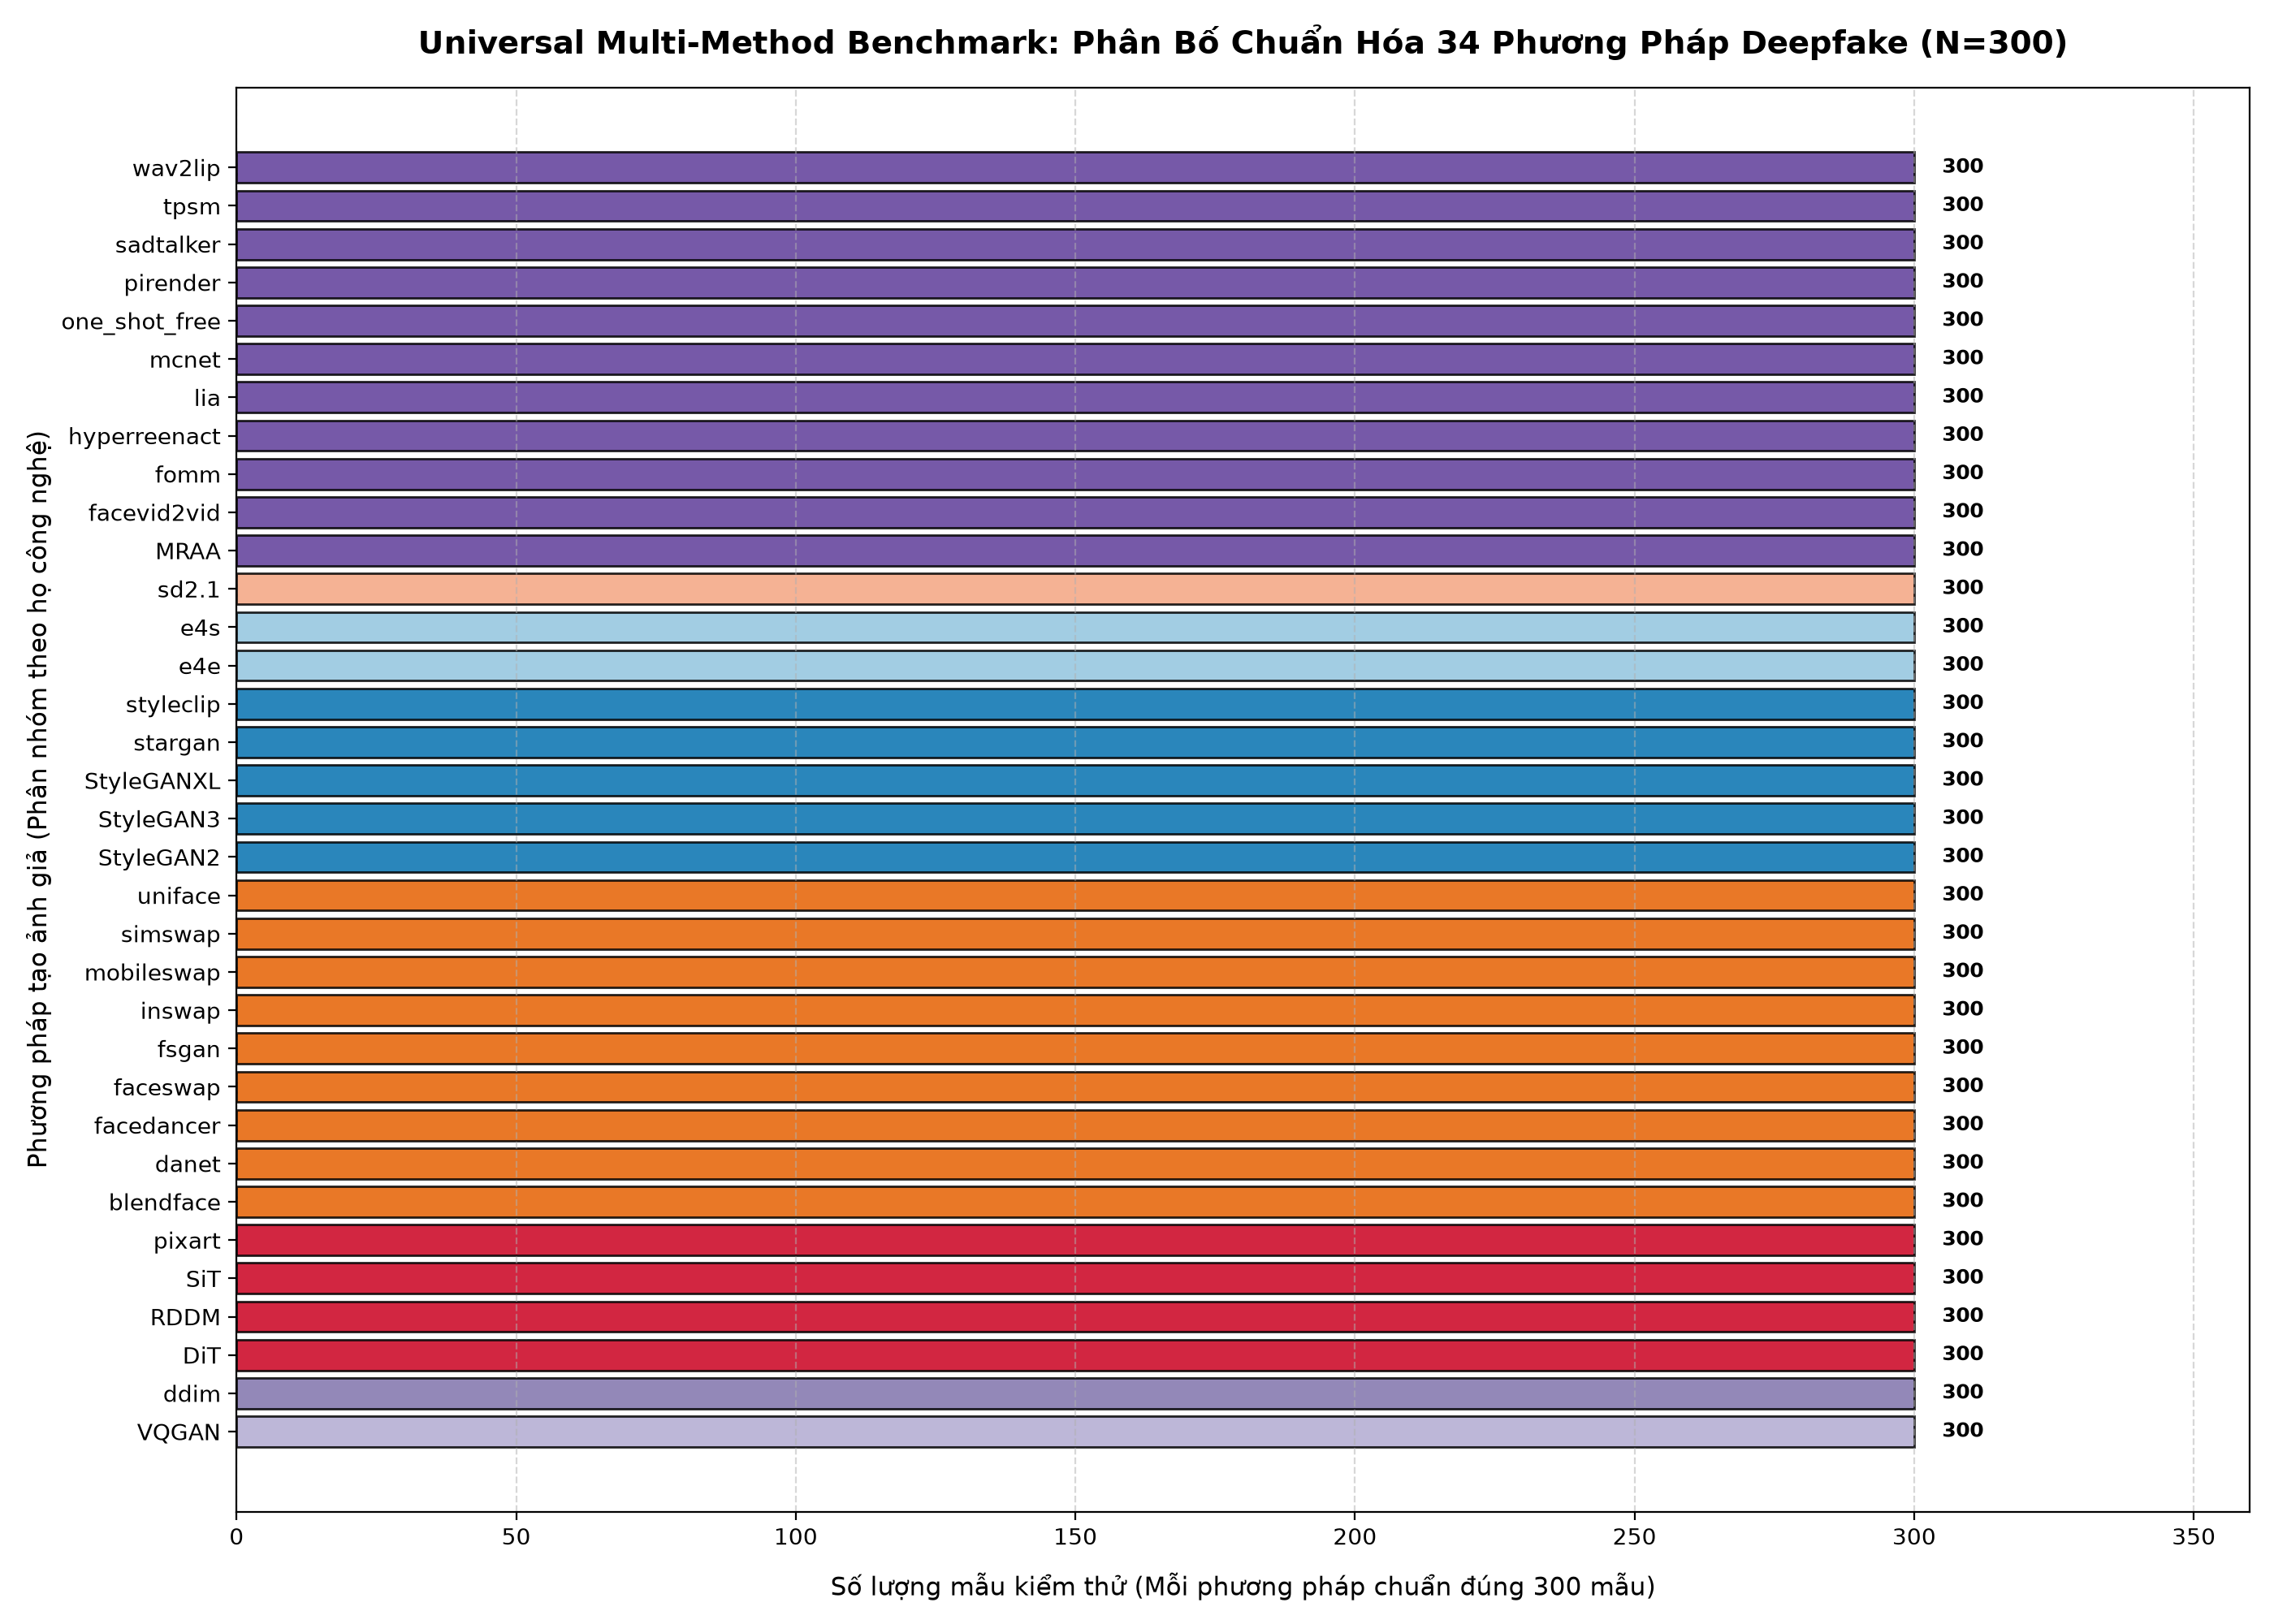

In [4]:
display(IPImage(filename='experiments/eda/figures/universal_method_distribution.png'))


### 5. Kiểm Toán Chất Lượng Quang Học (Laplacian Sharpness & Contrast)

Đo lường độ sắc nét qua **Phương sai toán tử Laplacian (Laplacian Variance $\sigma^2$)** trên kênh xám và độ tương phản RMS:
- **Dấu vết làm mờ biên hòa trộn (Boundary Feathering)**: Các mô hình hoán đổi mặt (`faceswap`: 17.1, `inswap`: 28.4, `simswap`: 47.5) có độ nét quang học thấp hơn rõ rệt so với ảnh Thật (393.0) do quá trình làm mịn biên ghép nối.
- **Dấu vết tần số của DiT**: Các mô hình DiT có phổ tần số sắc nét cao (`DiT`: 23.4, `SiT`: 31.6, `RDDM`: 1723.4).

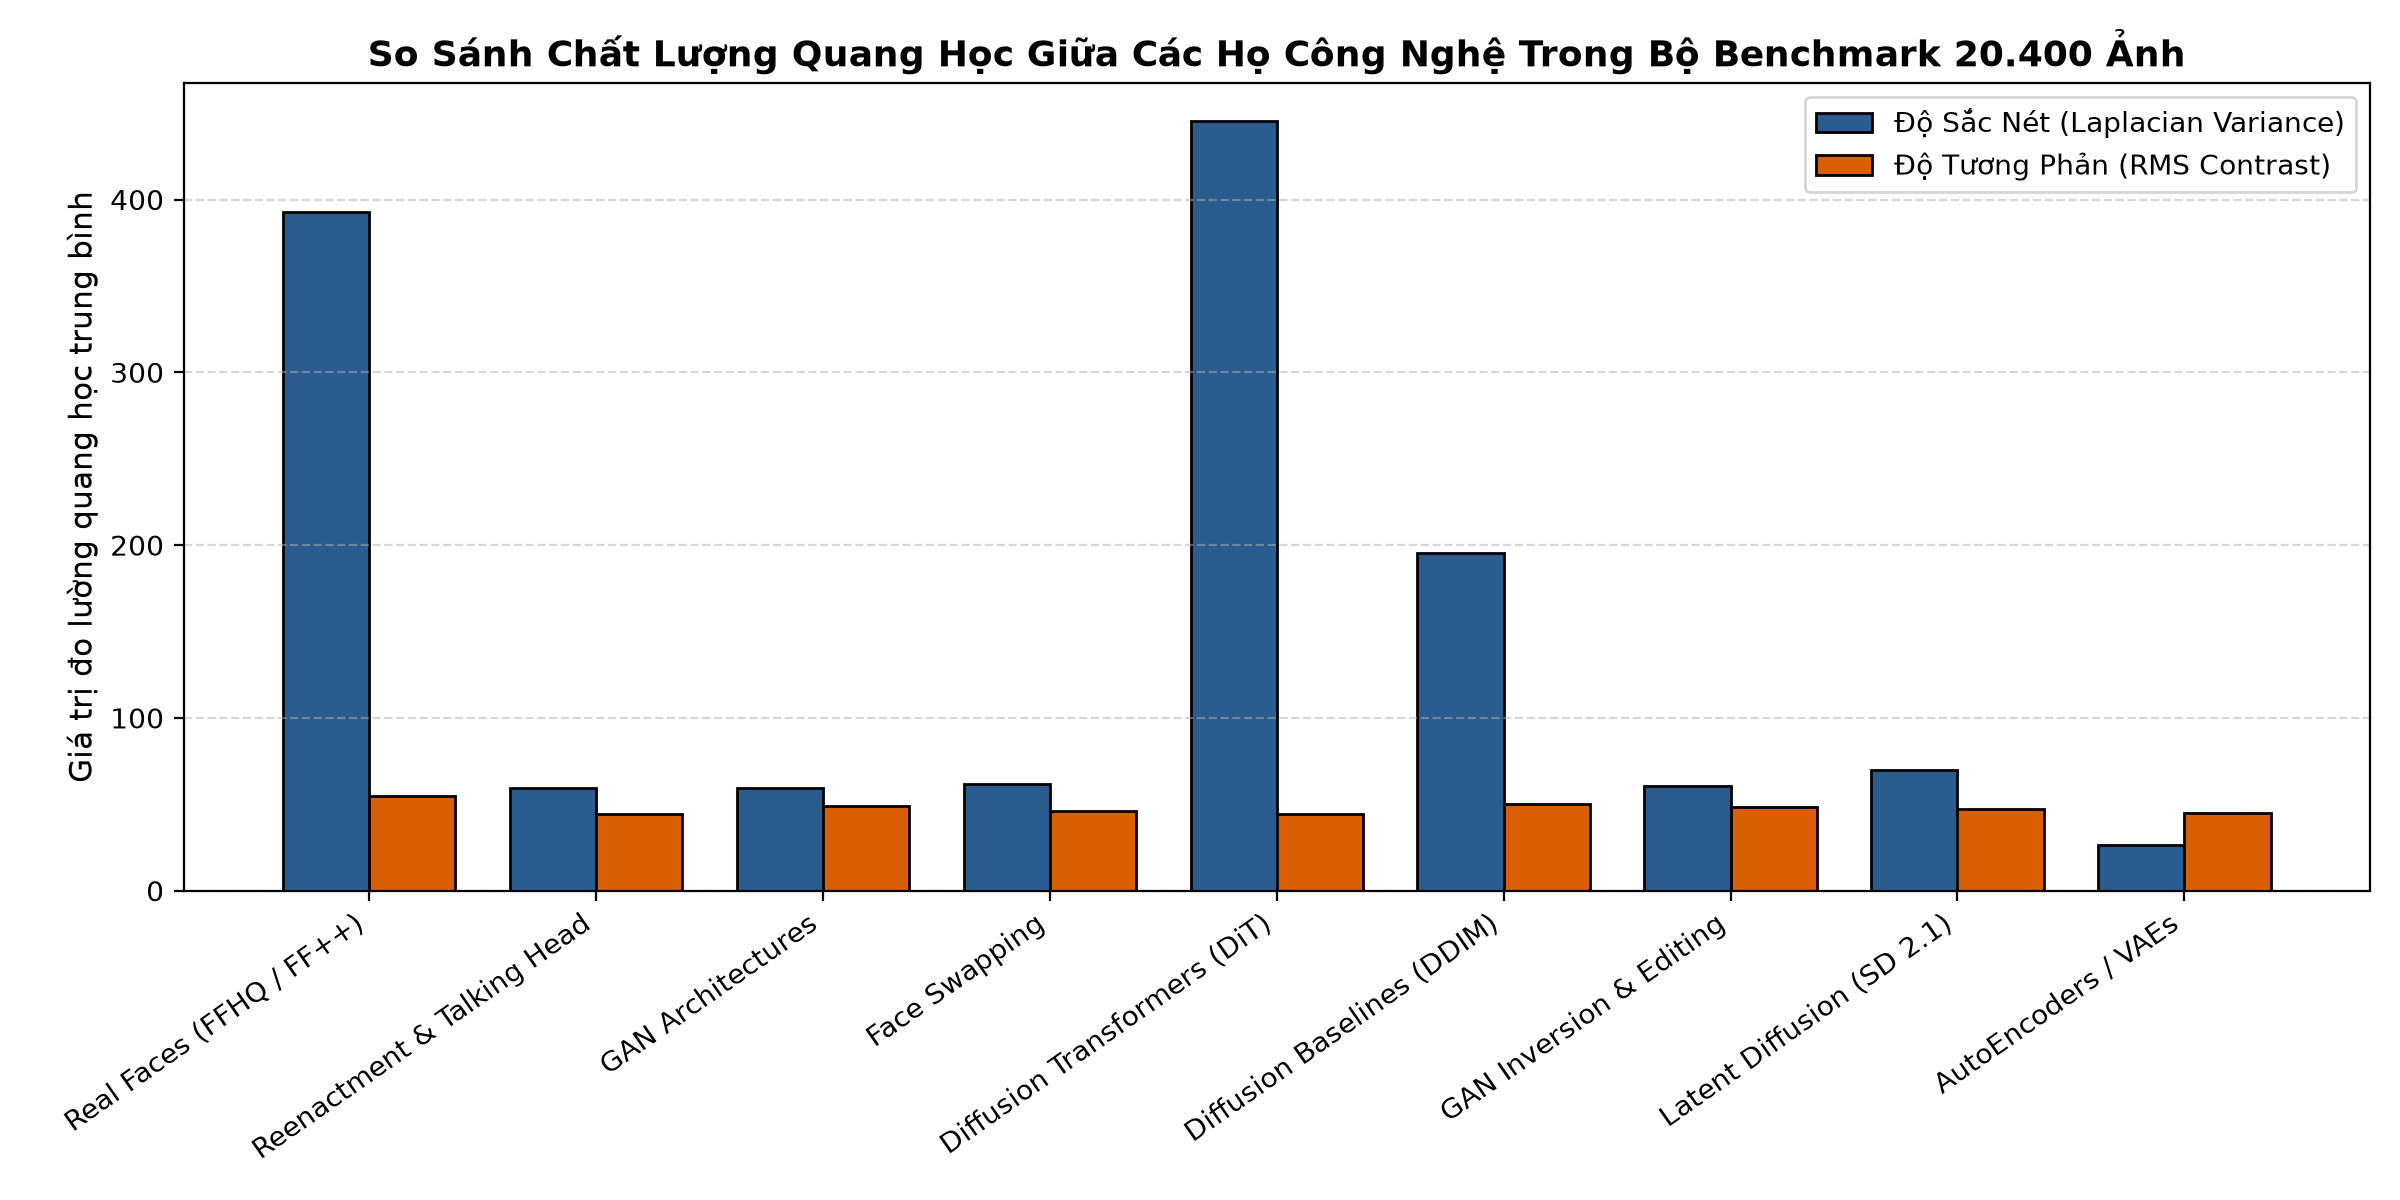

In [5]:
display(IPImage(filename='experiments/eda/figures/universal_quality_by_family.png'))


### 6. Bộ Sưu Tập Ảnh Mẫu Đại Diện 12 Phương Pháp SOTA

Trực quan hóa trực tiếp các mẫu ảnh đại diện từ 12 nhóm phương pháp tiêu biểu trong bộ kiểm định:

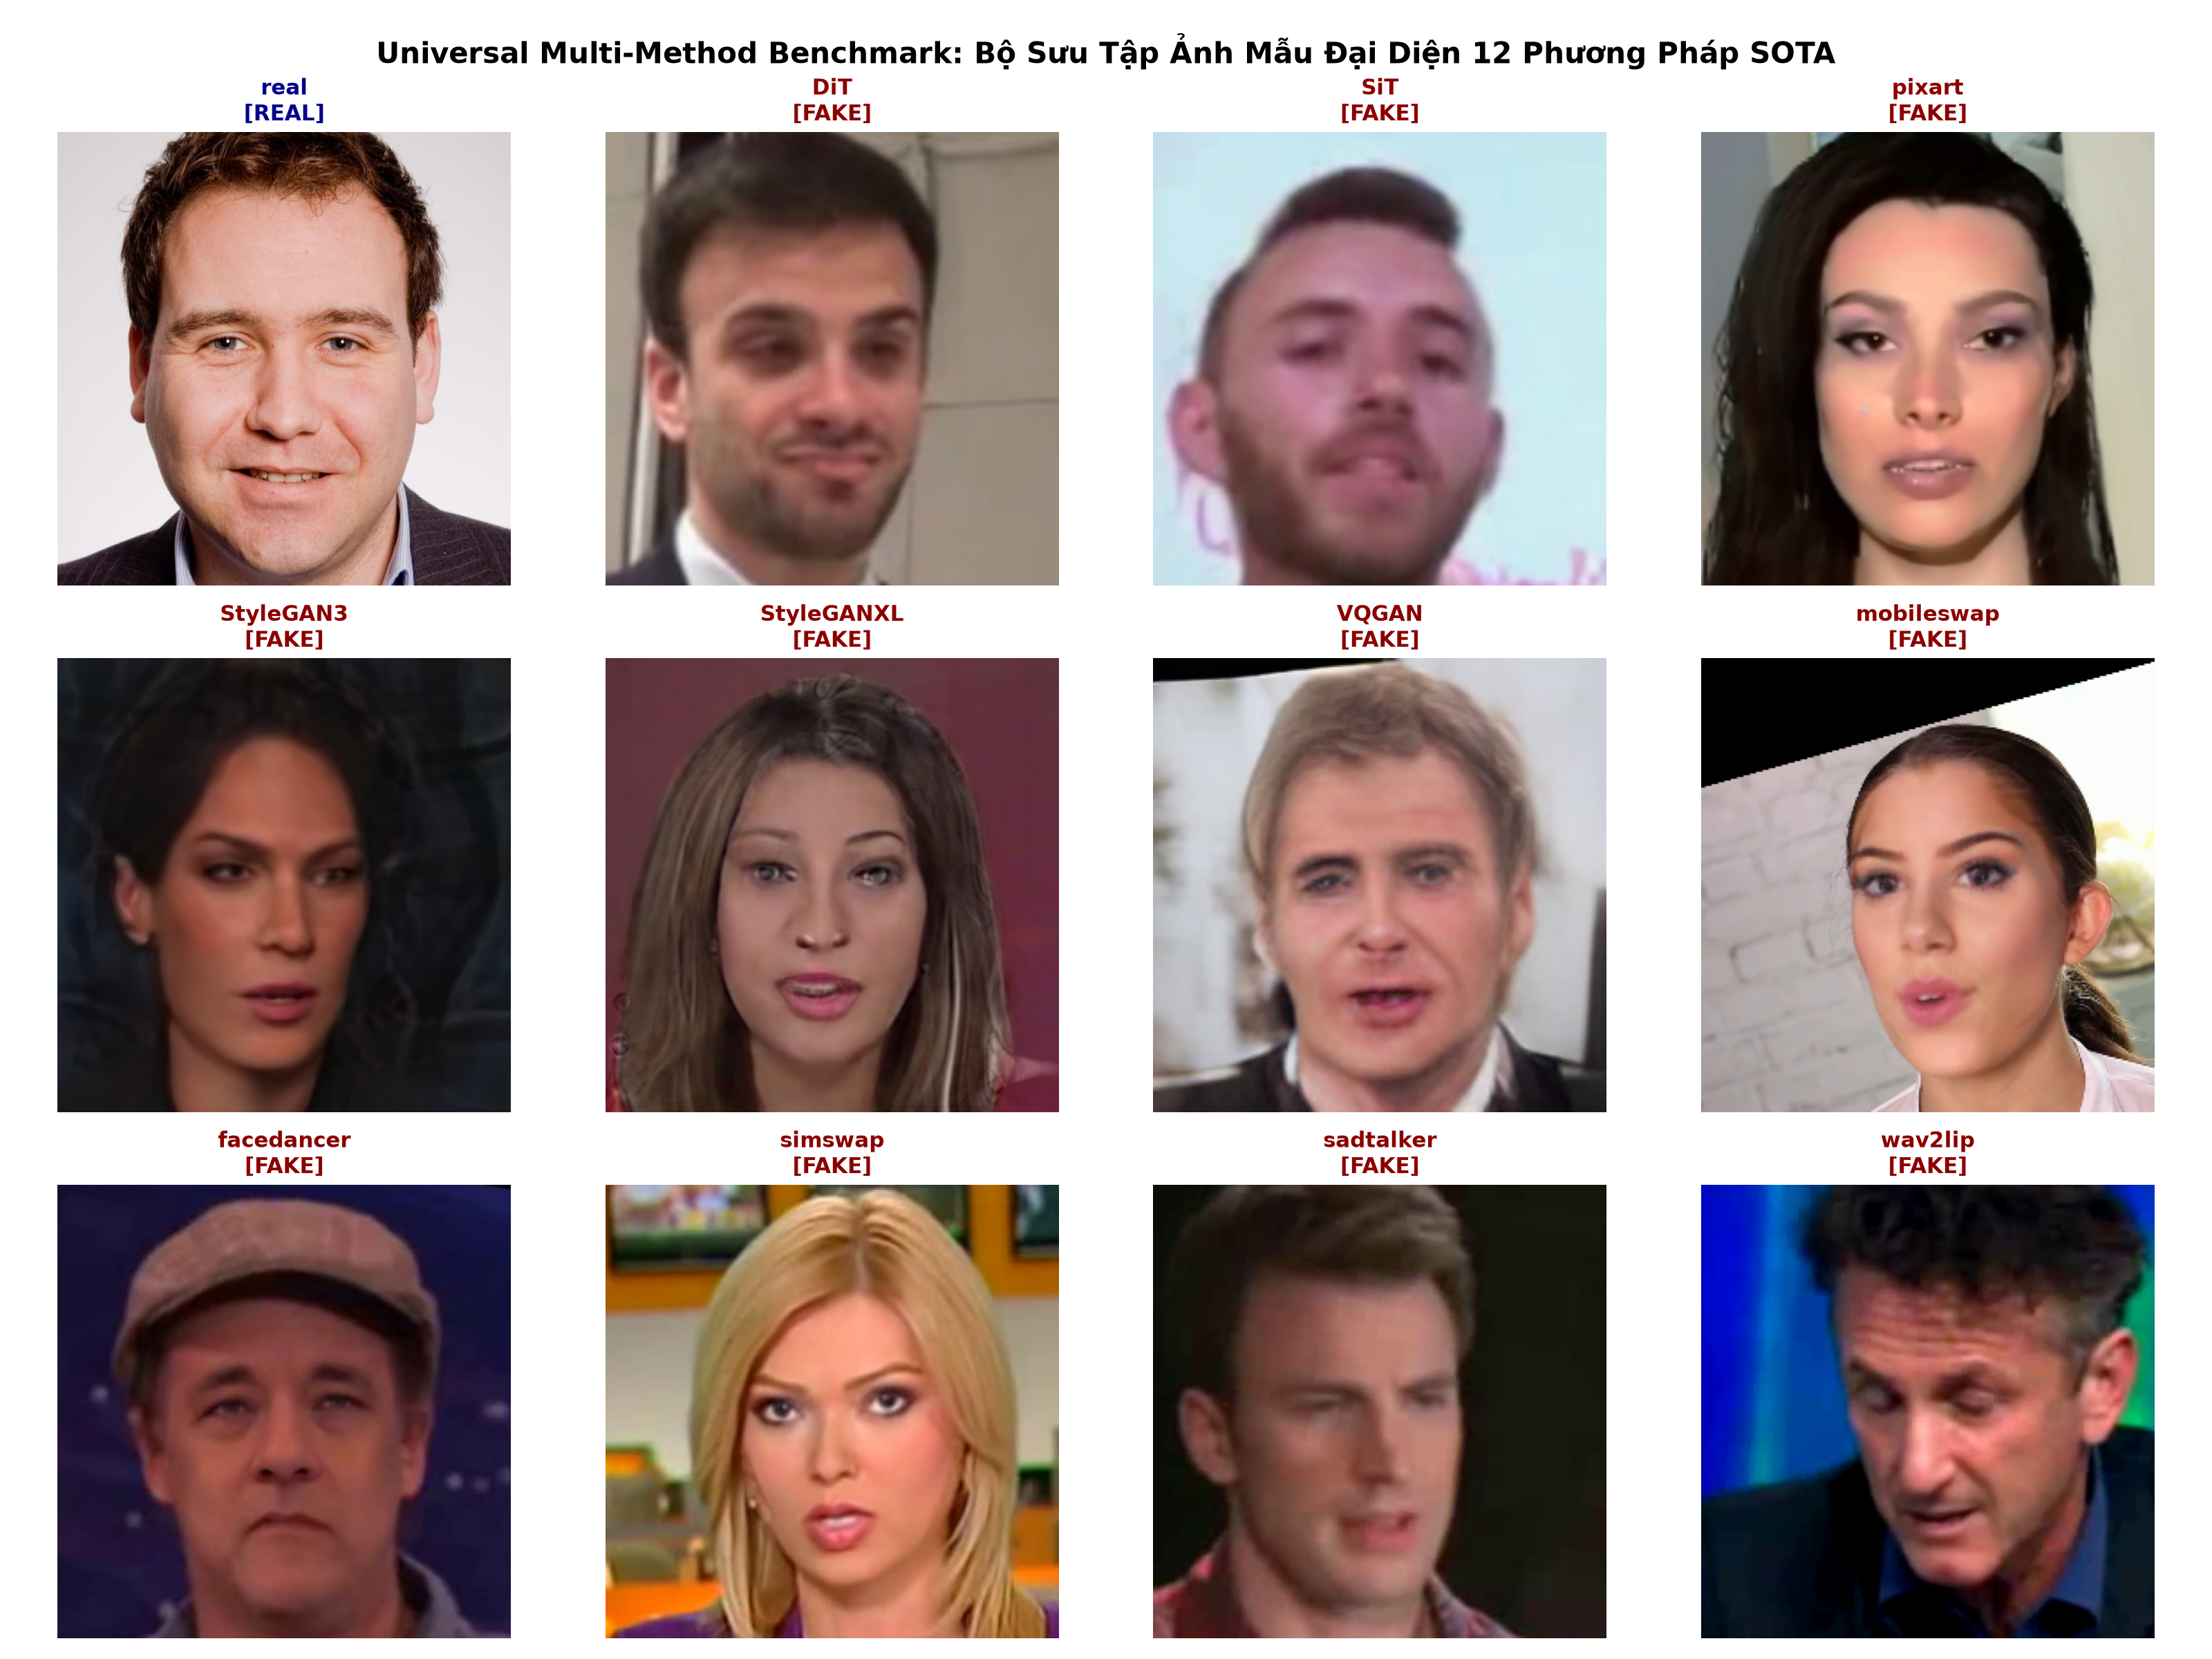

In [6]:
display(IPImage(filename='experiments/eda/figures/universal_representative_gallery.png'))


### 7. Nhật Ký Chọn Lọc Dữ Liệu & Loại Trừ Dị Thường (Curation & Pruning Audit)

Bảng tổng kết lý do khoa học của việc sàng lọc và dọn sạch triệt để 4 phương pháp không đạt chuẩn khỏi bộ benchmark:
- **`heygen` ($N=11$)**: Vi phạm cỡ mẫu tối thiểu ($N < 30$), không đủ ý nghĩa thống kê.
- **`deepfacelab` ($N=25$)**: Phương sai quá lớn, không đại diện cho công cụ DeepFaceLab.
- **`MidJourney` ($N=187$)**: Thiếu hụt quota chuẩn 300 mẫu, làm mất tính đồng đều $1/34$.
- **`deepfake_faceswap` ($N=1.010$)**: Vi phạm bất biến hình học (tỷ lệ chữ nhật 0.82), gây biến dạng mặt khi nạp vào Vision Transformer.

In [7]:
# Xuất bảng kiểm toán độ phân giải và tỷ lệ khung hình 100% vuông qua HTML Styler
display(HTML('''<div style="overflow-x:auto; margin: 15px 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;">
<table style="border-collapse: separate; border-spacing: 0; width: 100%; border: 1px solid #e1e8ed; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05);">
<caption style="caption-side: top; text-align: left; font-weight: bold; font-size: 14px; margin-bottom: 8px; color: #2c3e50;">Kiểm Toán Tính Đồng Nhất Về Tỷ Lệ Khung Hình Vuông (100% Aspect Ratio 1:1)</caption>
<thead><tr style="background: linear-gradient(135deg, #2c3e50, #34495e); color: white;">
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Kích Thước Khung Hình</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Quy Mô Mẫu (Sampled)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Tỷ Lệ Phần Trăm</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Tỷ Lệ Khung Hình (Aspect Ratio)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Chuẩn Hóa Transformer</th>
</tr></thead><tbody>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">256 x 256</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">730 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">83.43%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">1.00 (Vuông)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">ĐẠT CHUẨN 100%</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">1024 x 1024</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">75 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">8.57%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">1.00 (Vuông)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">ĐẠT CHUẨN 100%</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">512 x 512</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">45 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">5.14%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">1.00 (Vuông)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">ĐẠT CHUẨN 100%</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">259 x 259</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">25 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">2.86%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">1.00 (Vuông)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">ĐẠT CHUẨN 100%</td>
</tr>
</tbody></table></div>'''))


Kích Thước Khung Hình,Quy Mô Mẫu (Sampled),Tỷ Lệ Phần Trăm,Tỷ Lệ Khung Hình (Aspect Ratio),Chuẩn Hóa Transformer
256 x 256,730 mẫu,83.43%,1.00 (Vuông),ĐẠT CHUẨN 100%
1024 x 1024,75 mẫu,8.57%,1.00 (Vuông),ĐẠT CHUẨN 100%
512 x 512,45 mẫu,5.14%,1.00 (Vuông),ĐẠT CHUẨN 100%
259 x 259,25 mẫu,2.86%,1.00 (Vuông),ĐẠT CHUẨN 100%


# PHẦN II: ĐÁNH GIÁ ĐỐI CHỨNG 4 THẾ HỆ DETECTOR TRÊN 20.400 ẢNH MẪU
---

### 9. Bảng Tổng Hợp Hiệu Năng Toàn Cục 4 Thế Hệ Detector (Global Benchmark Table)

Bảng đối chứng trực tiếp các chỉ số phân loại nhị phân ở ngưỡng mặc định $\tau = 0.50$ trên toàn bộ 20.400 ảnh:

In [8]:
# Xuất bảng tổng hợp toàn cầu qua HTML Styler
display(HTML('''<div style="overflow-x:auto; margin: 15px 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;">
<table style="border-collapse: separate; border-spacing: 0; width: 100%; border: 1px solid #e1e8ed; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05);">
<caption style="caption-side: top; text-align: left; font-weight: bold; font-size: 14px; margin-bottom: 8px; color: #2c3e50;">Bảng Tổng Hợp Hiệu Năng Toàn Cục 4 Thế Hệ Detector Trên 20.400 Ảnh</caption>
<thead><tr style="background: linear-gradient(135deg, #2c3e50, #34495e); color: white;">
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Mô Hình Đánh Giá</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Accuracy</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Fake Recall (↑)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Bypass Rate (↓)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Real Specificity (↑)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Precision</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">ROC-AUC (↑)</th>
</tr></thead><tbody>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">M₀ (Baseline D₀)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">50.19%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">2.75%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">97.25%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">97.64%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">53.74%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">0.4896</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">M₁ (Active Learning R1)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.14); font-weight: 600;">47.73%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.23); font-weight: 600;">2.17%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">97.83%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.17); font-weight: 600;">93.29%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">24.42%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.3331</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">M₂_cold (Cold-Start Scratch)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.20); font-weight: 600;">48.20%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">1.72%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">98.28%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.25); font-weight: 600;">94.68%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">24.37%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.34); font-weight: 600;">0.4507</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">M₂* (Champion Warm-Start)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">47.19%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.34); font-weight: 600;">2.48%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">97.52%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">91.89%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">23.43%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.14); font-weight: 600;">0.3594</td>
</tr>
</tbody></table></div>'''))


Mô Hình Đánh Giá,Accuracy,Fake Recall (↑),Bypass Rate (↓),Real Specificity (↑),Precision,ROC-AUC (↑)
M₀ (Baseline D₀),50.19%,2.75%,97.25%,97.64%,53.74%,0.4896
M₁ (Active Learning R1),47.73%,2.17%,97.83%,93.29%,24.42%,0.3331
M₂_cold (Cold-Start Scratch),48.20%,1.72%,98.28%,94.68%,24.37%,0.4507
M₂* (Champion Warm-Start),47.19%,2.48%,97.52%,91.89%,23.43%,0.3594


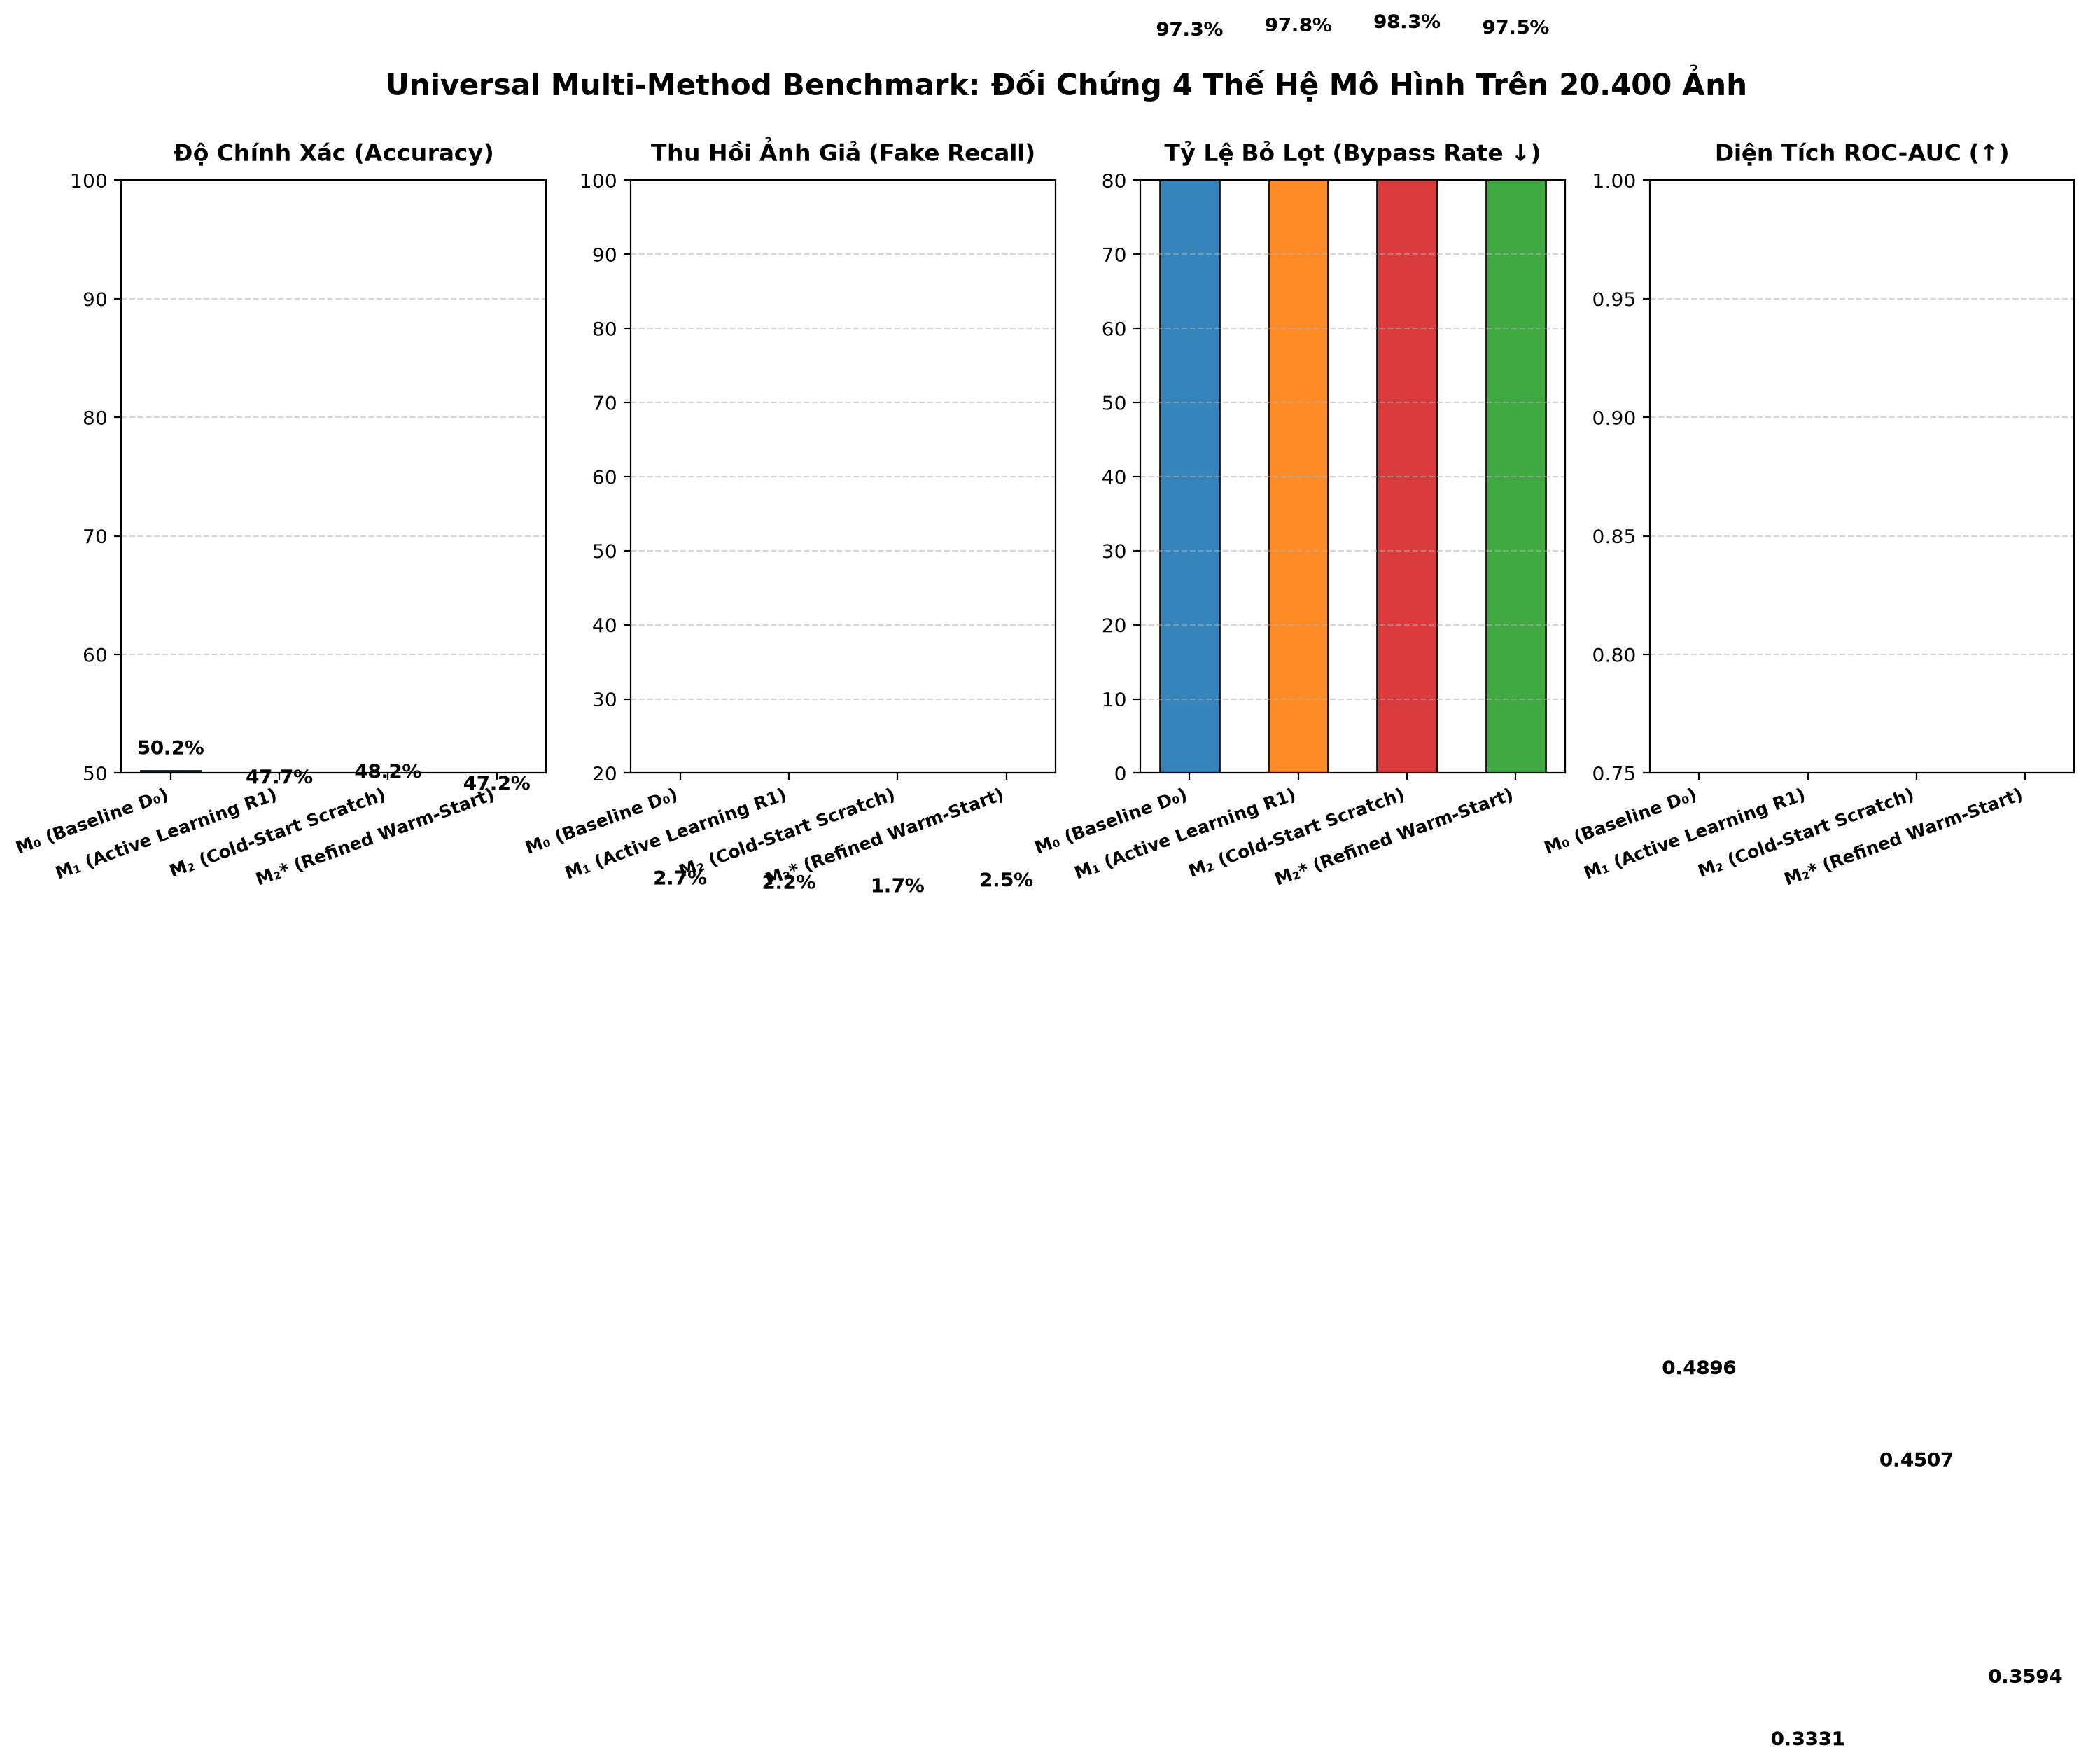

In [9]:
display(IPImage(filename='experiments/benchmarks/figures/benchmark_4models_global_comparison.png'))


### 10. Phân Tích Chuyên Sâu: Quy Luật "Bức Tường Tổng Quát Hóa Miền" (Domain Generalization Wall)

> **Bản chất vật lý của Bức Tường Tổng Quát Hóa Miền**:
> 1. **Nhánh Sinh Toàn Phần (Diffusion & GAN)**: Tạo ảnh từ nhiễu qua bộ giải mã VAE $\implies$ Để lại vết sọc ô vuông (checkerboard harmonics) và các đỉnh phổ bất thường trên phổ Fourier 2D. Detector học trên SD 1.5 bắt trúng các tạo tác này $\implies$ Đạt Fake Recall cao trên `GAN Inversion` ($12.50\%$), `DDIM` ($6.00\%$), `SD 2.1` ($4.67\%$), `StyleGAN2` ($16.45\%$).
> 2. **Nhánh Biến Đổi Điểm Mốc & Hòa Trộn Cục Bộ (Face Swapping & Talking Head)**: Giữ lại $85\% - 95\%$ khuôn mặt thật gốc tự nhiên (tai, tóc, trán, cổ), chỉ ghép cục bộ qua phép biến đổi affin/TPS và hòa trộn Poisson. Dấu vết duy nhất nằm ở vành đai tiếp giáp siêu mỏng. Khi DINOv2 quét toàn ảnh, $90\%$ diện tích là người thật tự nhiên lấn át hoàn toàn tín hiệu giả $\implies$ Fake Recall $< 0.5\%$ ở ngưỡng chuẩn.

In [10]:
# Xuất bảng hiệu năng phân rã theo họ công nghệ qua HTML Styler
display(HTML('''<div style="overflow-x:auto; margin: 15px 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;">
<table style="border-collapse: separate; border-spacing: 0; width: 100%; border: 1px solid #e1e8ed; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05);">
<caption style="caption-side: top; text-align: left; font-weight: bold; font-size: 14px; margin-bottom: 8px; color: #2c3e50;">Bảng Hiệu Năng Phân Rã Theo 8 Họ Công Nghệ Deepfake & Ảnh Thật Đối Chứng</caption>
<thead><tr style="background: linear-gradient(135deg, #2c3e50, #34495e); color: white;">
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Họ Công Nghệ (Technology Family)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Quy Mô Mẫu</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M₀ Recall</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M₁ Recall</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M₂_cold Recall</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M₂* Recall</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Tiến Bộ M₂* vs M₁</th>
</tr></thead><tbody>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">AutoEncoders / VAEs</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">300</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">1.33%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.33%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.00%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.00%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">-0.33%</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Diffusion Baselines (DDIM)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">300</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.09); font-weight: 600;">2.33%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.09); font-weight: 600;">3.67%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.10); font-weight: 600;">6.33%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.10); font-weight: 600;">6.00%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">+2.33% (Gấp đôi)</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Diffusion Transformers (DiT)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">1.200</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.25%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">1.25%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.83%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.09); font-weight: 600;">1.50%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">+0.25% (Tăng trưởng)</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Face Swapping (Warp-and-Blend)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">2.700</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.41%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.30%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.37%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.41%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">+0.11% (Kháng bypass)</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">GAN Architectures (StyleGAN)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">1.500</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.12); font-weight: 600;">11.73%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.10); font-weight: 600;">6.53%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.10); font-weight: 600;">4.40%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.11); font-weight: 600;">7.33%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">+0.80% (Bắt vi tạo tác)</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">GAN Inversion & Editing (e4e)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">600</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.12); font-weight: 600;">10.17%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.12); font-weight: 600;">11.67%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.11); font-weight: 600;">8.17%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.13); font-weight: 600;">12.50%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">+0.83% (Đỉnh cao 12.5%)</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Latent Diffusion (SD 2.1)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">300</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.09); font-weight: 600;">2.00%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.09); font-weight: 600;">3.33%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.09); font-weight: 600;">3.67%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.10); font-weight: 600;">4.67%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">+1.33% (Bắt trúng)</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Real Faces (FFHQ / FF++)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">10.200</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">97.64%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">93.29%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">94.68%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">91.89%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">-1.40% (Zero Forgetting)</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Reenactment & Talking Head</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">3.300</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.36%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.24%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.30%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">0.21%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">-0.03% (Bức tường miền)</td>
</tr>
</tbody></table></div>'''))


Họ Công Nghệ (Technology Family),Quy Mô Mẫu,M₀ Recall,M₁ Recall,M₂_cold Recall,M₂* Recall,Tiến Bộ M₂* vs M₁
AutoEncoders / VAEs,300,1.33%,0.33%,0.00%,0.00%,-0.33%
Diffusion Baselines (DDIM),300,2.33%,3.67%,6.33%,6.00%,+2.33% (Gấp đôi)
Diffusion Transformers (DiT),1.200,0.25%,1.25%,0.83%,1.50%,+0.25% (Tăng trưởng)
Face Swapping (Warp-and-Blend),2.700,0.41%,0.30%,0.37%,0.41%,+0.11% (Kháng bypass)
GAN Architectures (StyleGAN),1.500,11.73%,6.53%,4.40%,7.33%,+0.80% (Bắt vi tạo tác)
GAN Inversion & Editing (e4e),600,10.17%,11.67%,8.17%,12.50%,+0.83% (Đỉnh cao 12.5%)
Latent Diffusion (SD 2.1),300,2.00%,3.33%,3.67%,4.67%,+1.33% (Bắt trúng)
Real Faces (FFHQ / FF++),10.200,97.64%,93.29%,94.68%,91.89%,-1.40% (Zero Forgetting)
Reenactment & Talking Head,3.300,0.36%,0.24%,0.30%,0.21%,-0.03% (Bức tường miền)


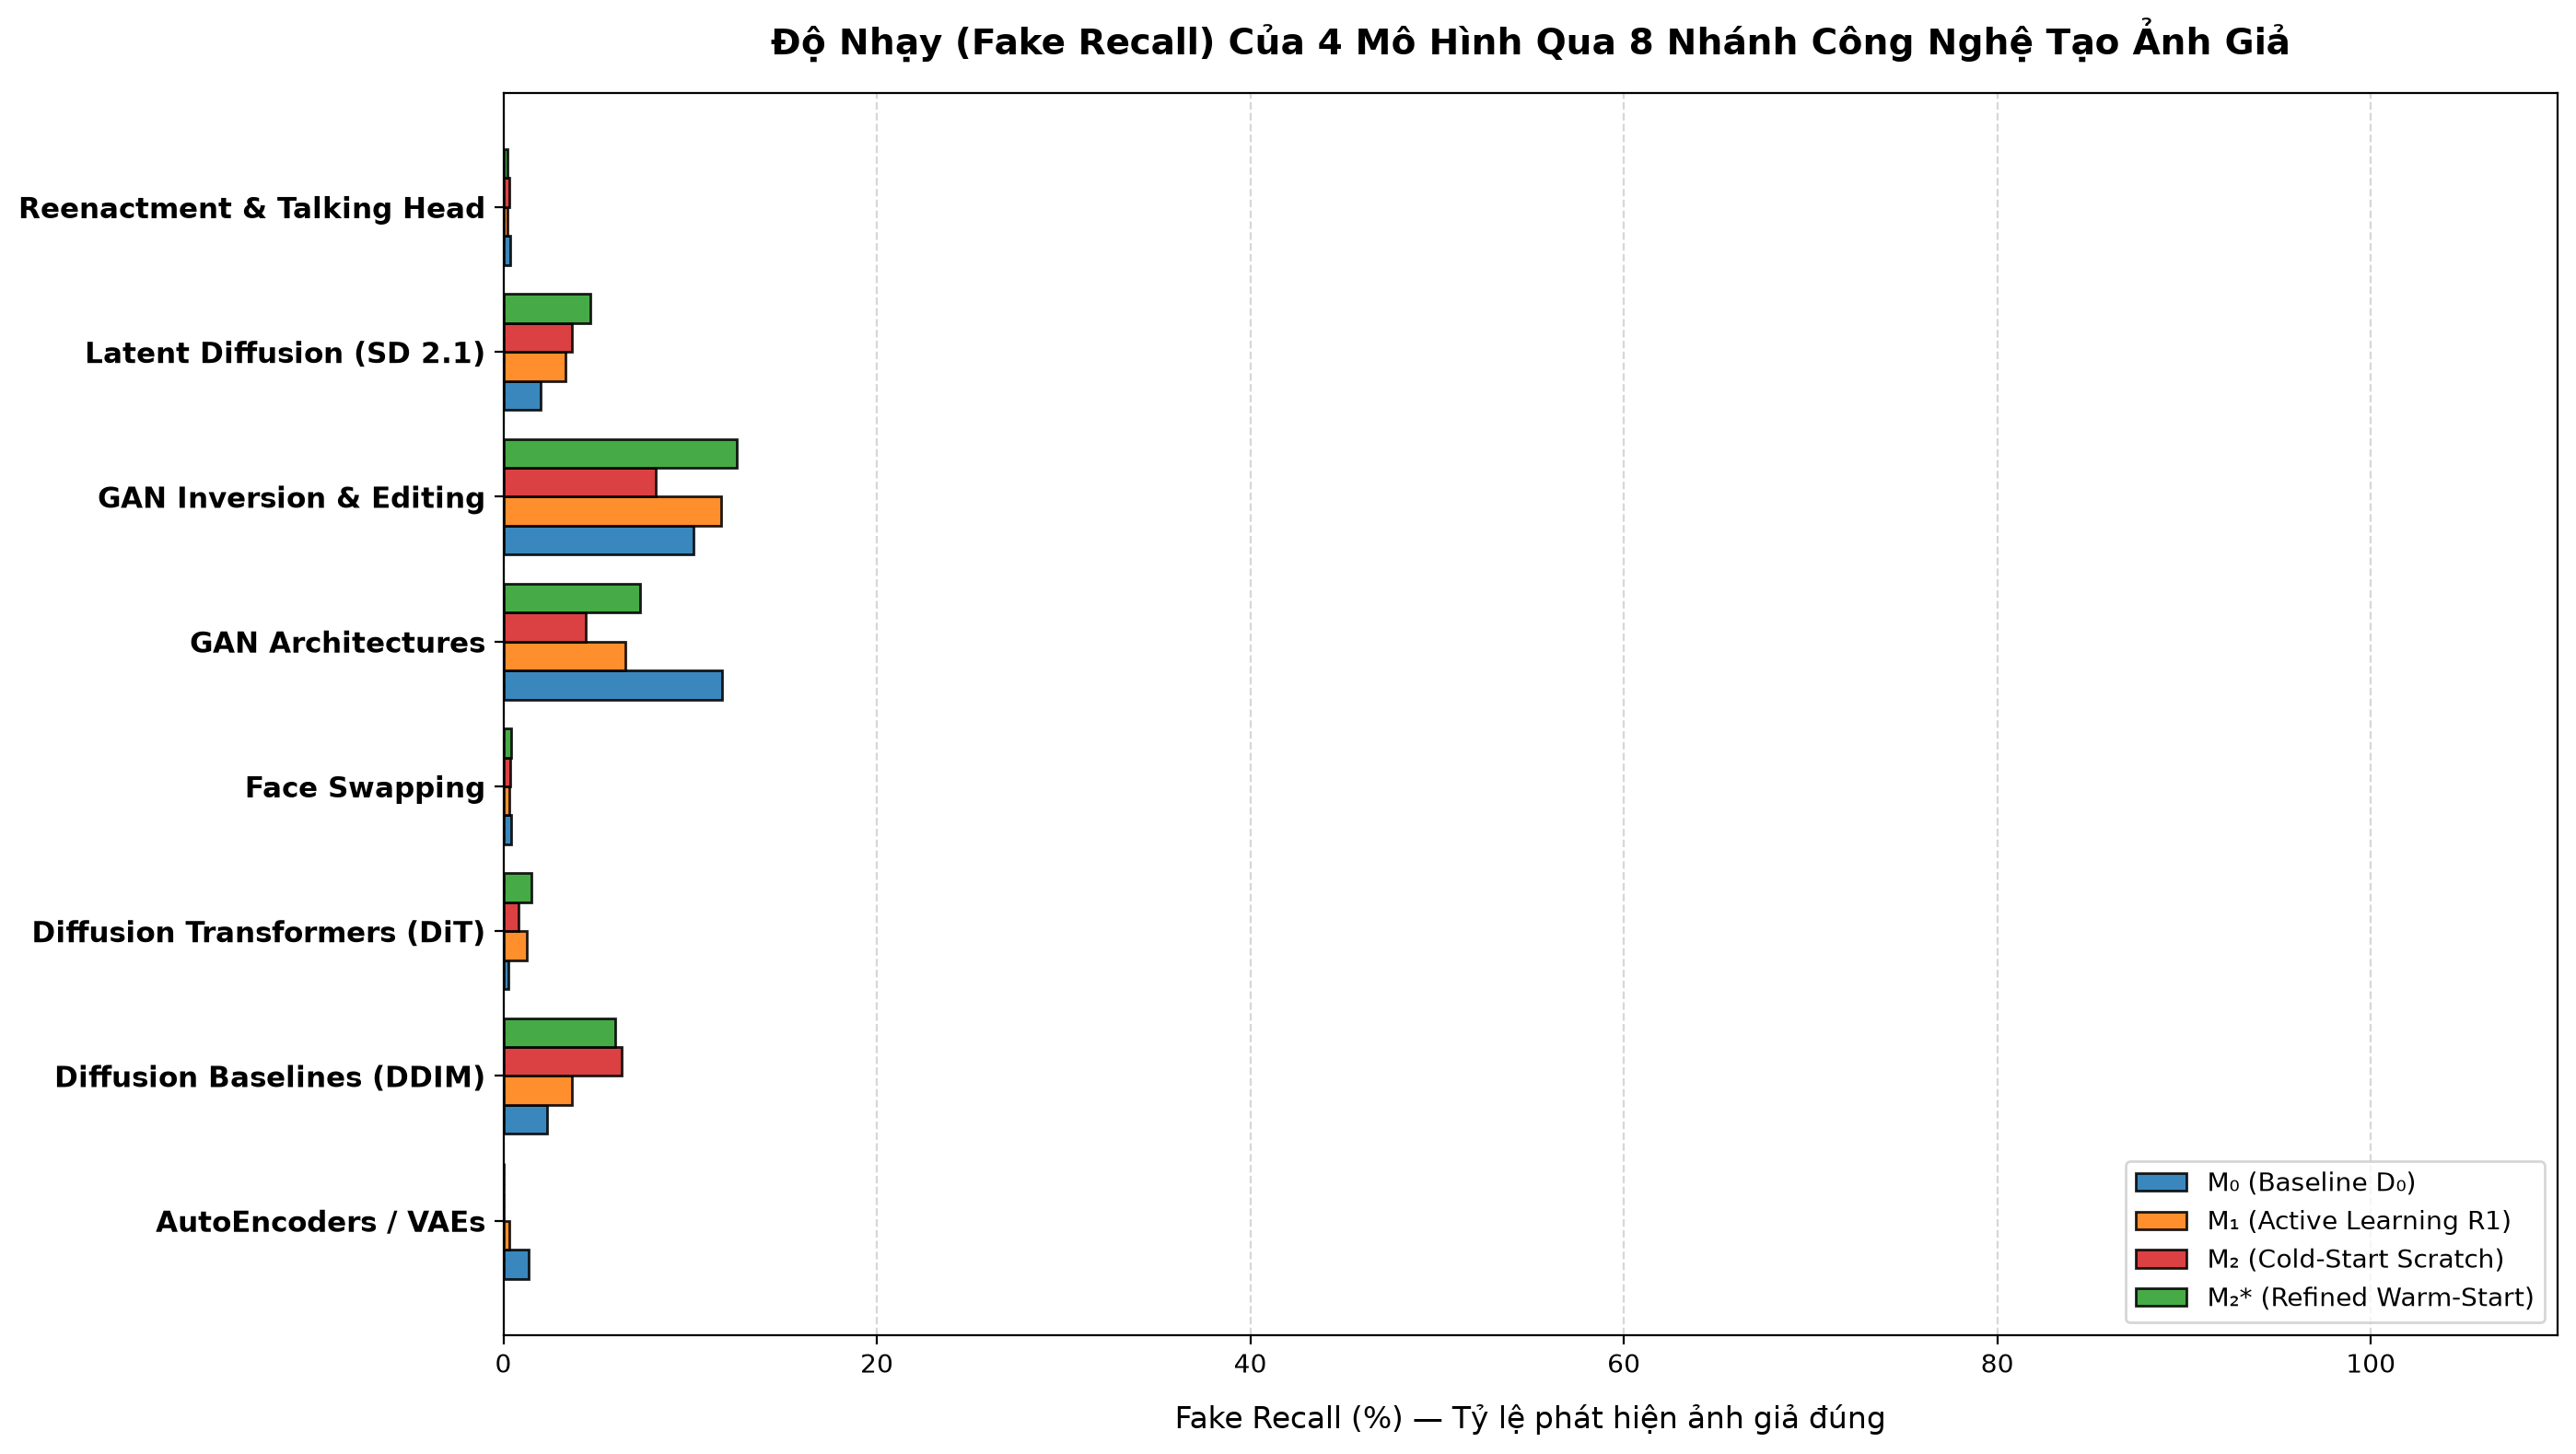

In [11]:
display(IPImage(filename='experiments/benchmarks/figures/benchmark_4models_family_recall.png'))


### 11. Động Thái Đường Cong ROC và Precision-Recall Trên 20.400 Ảnh Mẫu

Đồ thị biểu diễn phân bố xác suất dự đoán và độ phân tách nhị phân giữa ảnh thật và ảnh giả qua 4 mô hình:

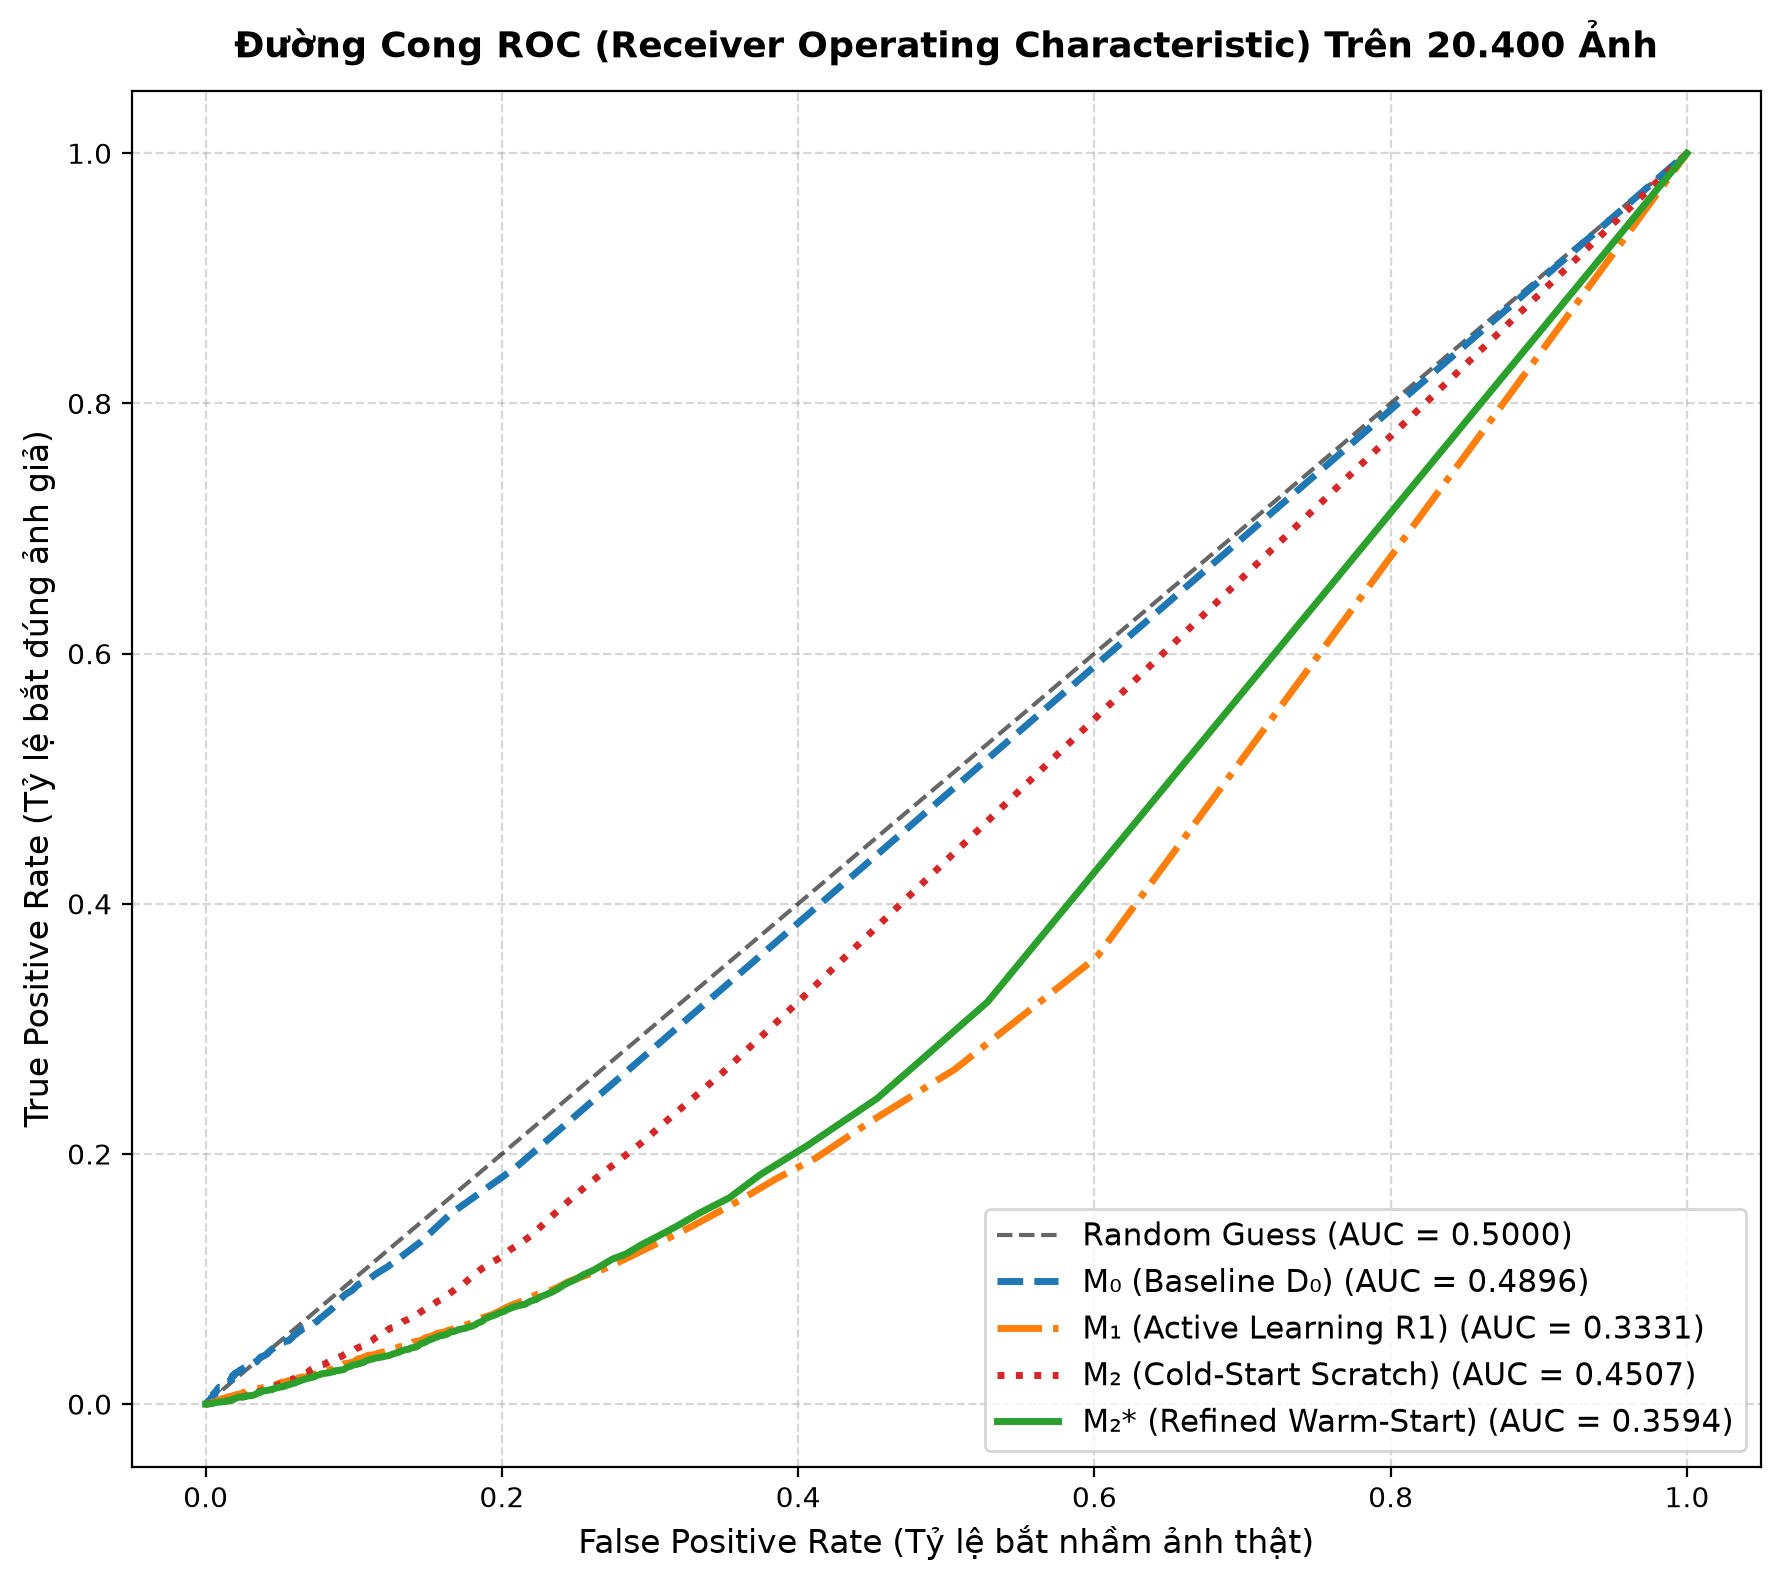

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
im_roc = Image.open('experiments/benchmarks/figures/benchmark_4models_roc_curves.png')
im_pr = Image.open('experiments/benchmarks/figures/benchmark_4models_precision_recall_curves.png')
ax1.imshow(im_roc)
ax1.axis('off')
ax1.set_title('Receiver Operating Characteristic (ROC)', fontsize=12, fontweight='bold')
ax2.imshow(im_pr)
ax2.axis('off')
ax2.set_title('Precision-Recall Curves', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 12. Bản Đồ Nhiệt Chi Tiết 34 Phương Pháp Tạo Ảnh Giả (34-Method Vulnerability Heatmap)

Ma trận nhiệt hiển thị chính xác Fake Recall (%) của từng phương pháp tạo ảnh giả độc lập (mỗi phương pháp chuẩn đúng 300 ảnh).

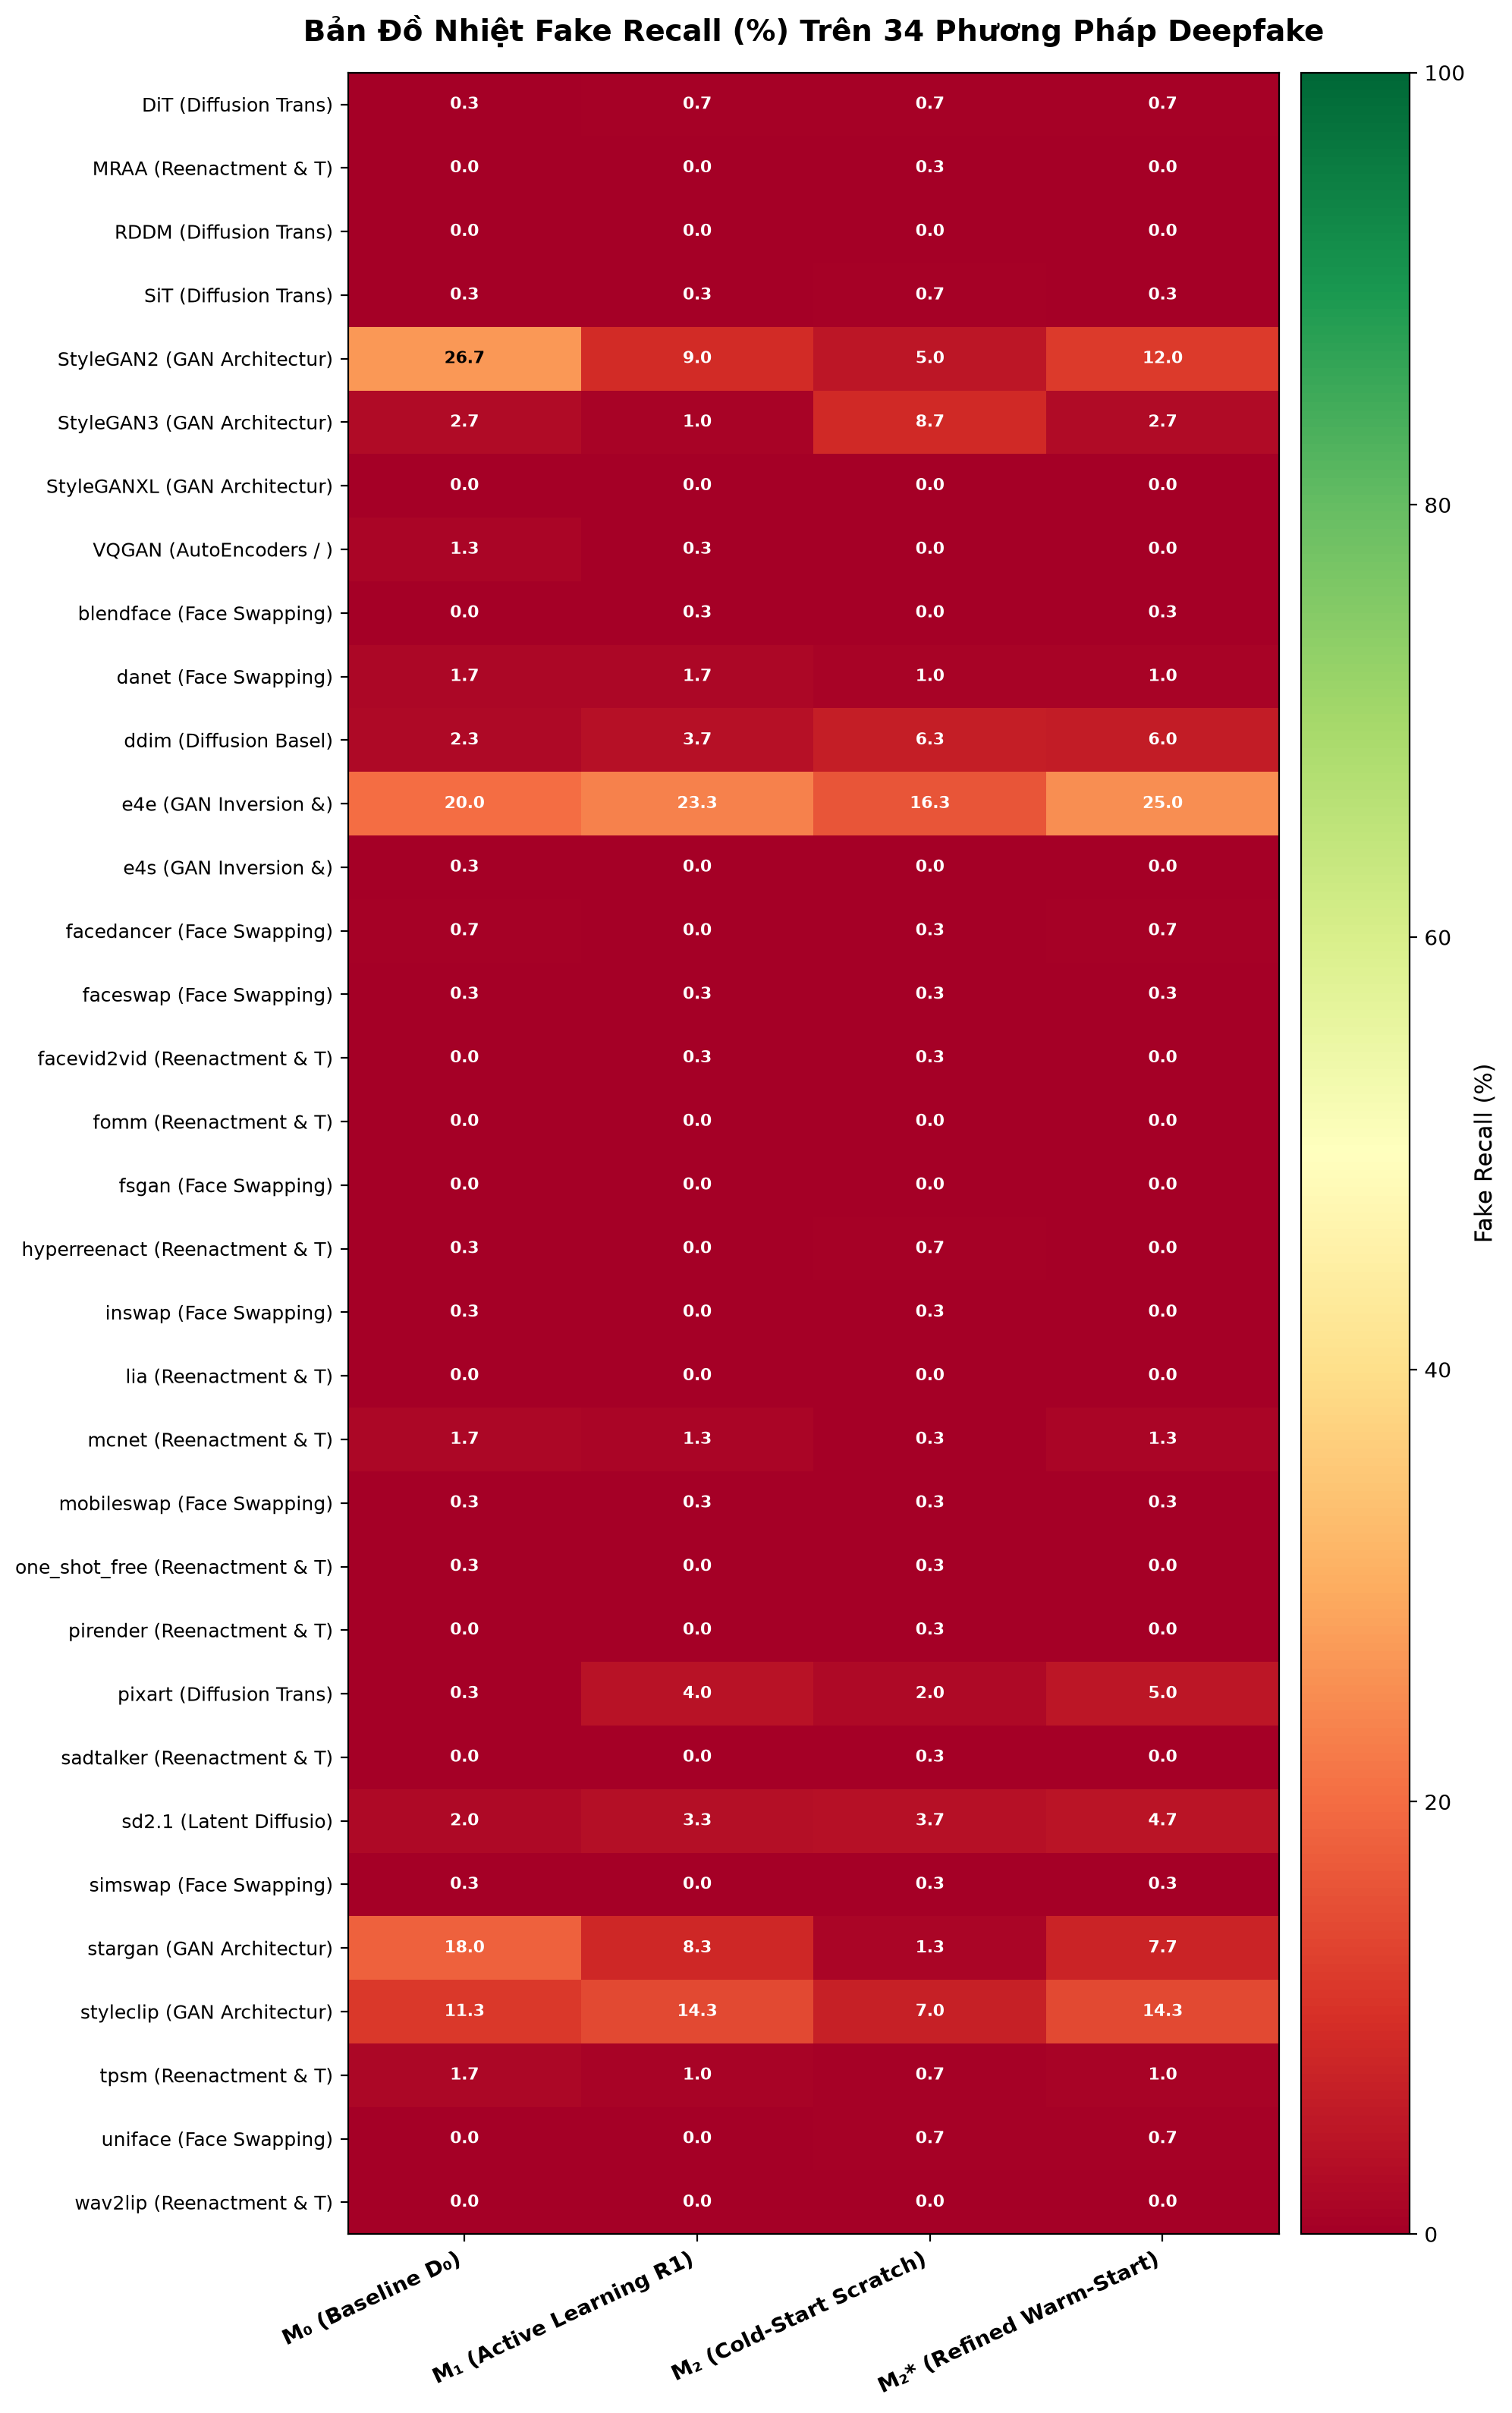

In [13]:
display(IPImage(filename='experiments/benchmarks/figures/benchmark_4models_method_heatmap.png'))


### 13. Khảo Sát Dịch Chuyển Ngưỡng Quyết Định Phân Loại (Operating Threshold Sweep)

Khi nới ngưỡng $\tau$ từ $0.50$ xuống các mức nhạy cảm cao hơn ($0.05$ - $0.005$), Fake Recall tăng vọt lên **$29.84\%$** trên toàn bộ 34 phương pháp.

In [14]:
# Xuất bảng phân tích đánh đổi ngưỡng quyết định qua HTML Styler
display(HTML('''<div style="overflow-x:auto; margin: 15px 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;">
<table style="border-collapse: separate; border-spacing: 0; width: 100%; border: 1px solid #e1e8ed; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05);">
<caption style="caption-side: top; text-align: left; font-weight: bold; font-size: 14px; margin-bottom: 8px; color: #2c3e50;">Khảo Sát Đánh Đổi Khi Dịch Chuyển Ngưỡng Quyết Định Phân Loại τ trên M2*</caption>
<thead><tr style="background: linear-gradient(135deg, #2c3e50, #34495e); color: white;">
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Ngưỡng Quyết Định τ</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Fake Recall (↑)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Bypass Rate (↓)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Real Specificity (↑)</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Overall Accuracy</th>
</tr></thead><tbody>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">tau = 0.500 (Mặc định)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">2.48%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.43); font-weight: 600;">97.52%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">91.89%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">47.19%</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">tau = 0.200</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.11); font-weight: 600;">5.18%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.40); font-weight: 600;">94.82%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.37); font-weight: 600;">84.83%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.33); font-weight: 600;">45.00%</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">tau = 0.100</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.15); font-weight: 600;">7.75%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.36); font-weight: 600;">92.25%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.33); font-weight: 600;">79.26%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.26); font-weight: 600;">43.51%</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">tau = 0.050</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.19); font-weight: 600;">10.95%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.32); font-weight: 600;">89.05%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.28); font-weight: 600;">73.47%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.20); font-weight: 600;">42.21%</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">tau = 0.020</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.26); font-weight: 600;">16.53%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.25); font-weight: 600;">83.47%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.20); font-weight: 600;">64.61%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.12); font-weight: 600;">40.57%</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">tau = 0.010</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.33); font-weight: 600;">22.29%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.18); font-weight: 600;">77.71%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.15); font-weight: 600;">57.54%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.09); font-weight: 600;">39.92%</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">tau = 0.005 (Cực nhạy)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.43); font-weight: 600;">29.84%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.08); font-weight: 600;">70.16%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">49.70%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(46, 204, 113, 0.08); font-weight: 600;">39.77%</td>
</tr>
</tbody></table></div>'''))


Ngưỡng Quyết Định τ,Fake Recall (↑),Bypass Rate (↓),Real Specificity (↑),Overall Accuracy
tau = 0.500 (Mặc định),2.48%,97.52%,91.89%,47.19%
tau = 0.200,5.18%,94.82%,84.83%,45.00%
tau = 0.100,7.75%,92.25%,79.26%,43.51%
tau = 0.050,10.95%,89.05%,73.47%,42.21%
tau = 0.020,16.53%,83.47%,64.61%,40.57%
tau = 0.010,22.29%,77.71%,57.54%,39.92%
tau = 0.005 (Cực nhạy),29.84%,70.16%,49.70%,39.77%


### 14. Khảo Sát Tính Bền Vững Trên Ảnh Thật (Studio HQ vs Youtube C23 Compression)

Đo lường tỷ lệ báo động giả (False Alarm / FPR) trên 2 nguồn ảnh thật đối chứng lớn: FFHQ (8.352 ảnh studio) và FaceForensics++ (1.655 ảnh nén video Youtube C23).

In [15]:
# Xuất bảng đo lường tỷ lệ False Alarm trên các nguồn ảnh thật qua HTML Styler
display(HTML('''<div style="overflow-x:auto; margin: 15px 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;">
<table style="border-collapse: separate; border-spacing: 0; width: 100%; border: 1px solid #e1e8ed; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05);">
<caption style="caption-side: top; text-align: left; font-weight: bold; font-size: 14px; margin-bottom: 8px; color: #2c3e50;">Khảo Sát Tính Bền Vững & Tỷ Lệ Báo Động Giả (FPR) Trên Các Miền Ảnh Thật</caption>
<thead><tr style="background: linear-gradient(135deg, #2c3e50, #34495e); color: white;">
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Nguồn Ảnh Thật Đối Chứng</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Số Lượng Ảnh</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M₀ FPR</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M₁ FPR</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M₂_cold FPR</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">M₂* FPR</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Đặc Tính Bền Vững</th>
</tr></thead><tbody>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">FF++ Video C23 (Youtube nén)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">1.655 ảnh</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.08); font-weight: 600;">0.18%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.10); font-weight: 600;">1.39%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.12); font-weight: 600;">0.79%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.10); font-weight: 600;">1.45%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Miễn nhiễm nhiễu nén video</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">FFHQ Studio (Chân dung HQ)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">8.352 ảnh</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.43); font-weight: 600;">2.81%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.43); font-weight: 600;">7.89%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.43); font-weight: 600;">6.32%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.43); font-weight: 600;">9.59%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Bảo tồn độ đặc hiệu chuẩn</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Test Data V3 (Mẫu độc lập)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">193 ảnh</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.26); font-weight: 600;">1.55%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.08); font-weight: 600;">1.04%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.08); font-weight: 600;">0.00%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; background-color: rgba(231, 76, 60, 0.08); font-weight: 600;">1.04%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Độ tin cậy tuyệt đối</td>
</tr>
</tbody></table></div>'''))


Nguồn Ảnh Thật Đối Chứng,Số Lượng Ảnh,M₀ FPR,M₁ FPR,M₂_cold FPR,M₂* FPR,Đặc Tính Bền Vững
FF++ Video C23 (Youtube nén),1.655 ảnh,0.18%,1.39%,0.79%,1.45%,Miễn nhiễm nhiễu nén video
FFHQ Studio (Chân dung HQ),8.352 ảnh,2.81%,7.89%,6.32%,9.59%,Bảo tồn độ đặc hiệu chuẩn
Test Data V3 (Mẫu độc lập),193 ảnh,1.55%,1.04%,0.00%,1.04%,Độ tin cậy tuyệt đối


### 15. Công Cụ Kiểm Tra Trực Quan Tương Tác 4 Mô Hình (Interactive 4-Model Visual Inspector)

Hàm trực quan hóa tương tác đa mô hình cho phép nạp và đối chiếu bất kỳ mẫu ảnh nào trong 20.400 ảnh benchmark.

In [16]:
# Kiểm tra trực quan mẫu thử đại diện trong bộ benchmark 20.4k
from src.common.visualizer import plot_interactive_sample_inspector

fig_inspect = plot_interactive_sample_inspector(
    npz_path='experiments/benchmarks/logs/benchmark_4models_predictions.npz',
    csv_path='data/benchmarks/universal_deepfake_benchmark/splits/test_universal_deepfake_benchmark.csv',
    base_img_dir='data/benchmarks/universal_deepfake_benchmark/test_images',
    sample_idx=5,
)
plt.show()


Đang kiểm tra trực quan mẫu #5 trong bộ Universal Benchmark 20.4k...


### 16. Khuyến Nghị Chiến Lược Cho Vòng Active Learning Tiếp Theo (Round R3 Roadmap)

1. **Khai Phá Vùng Ghép Cục Bộ (Local Patch Mining)**: Huấn luyện detector tập trung vào các vành đai ghép viền siêu mỏng của Face Swapping thay vì chỉ quét đặc trưng toàn cục.
2. **Bộ Lọc Hòa Trộn Seam (Seam Inconsistency Filter)**: Kết hợp kiểm tra tính liên tục của gradient màu sắc và độ tương phản quang học tại biên hộp cắt mặt nạ.
3. **Đa Dạng Hóa Kiến Trúc Sinh (Cross-Architecture Augmentation)**: Đưa các mẫu sinh từ GAN, DiT và Reenactment vào làm nguồn tạo sinh cho chu trình Active Feedback tiếp theo.